**Question:** Should we impute `price`, `beds`, and `bathrooms` for the final two
snapshots (2025-06-24, 2025-09-26) using values from the same `listing_id + host_id`
in the first four snapshots, or drop pricing altogether given ~33 % missing data?

**Plan**

1. Confirm null rates by snapshot for all three columns
2. Size the imputable universe (listings in snaps 5--6 with history in snaps 1--4)
3. Test `beds` / `bathrooms` stability -- are they constant across snaps 1--4?
4. Measure `price` consistency via coefficient of variation (CV)
5. Summarise the decision
6. Write imputation table to DB
7. ADR outlier detection (IQR cross-sectional + temporal spikes)
8. Occupancy anomalies (saturated / zero flags)
9. Data gap analysis (calendar coverage, missing prices, listing churn)
10. Combined quality flags → `airbnb_features.listing_quality_flags`
11. Impact analysis: all listings vs. clean (unflagged) subset

In [1]:
from __future__ import annotations
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sqlalchemy import text
from browardairbnb.config import load_project_env, get_engine

load_project_env()
engine = get_engine()

EARLY = ('2024-06-26', '2024-09-23', '2024-12-25', '2025-03-19')
LATE  = ('2025-06-24', '2025-09-26')

TABLE     = 'airbnb_cleaned.listings_property_cleaned'
CAL_TABLE = 'airbnb_cleaned.calendar_cleaned'
early_in  = ', '.join(f"'{s}'" for s in EARLY)
late_in   = ', '.join(f"'{s}'" for s in LATE)

## 1  Null-rate confirmation by snapshot

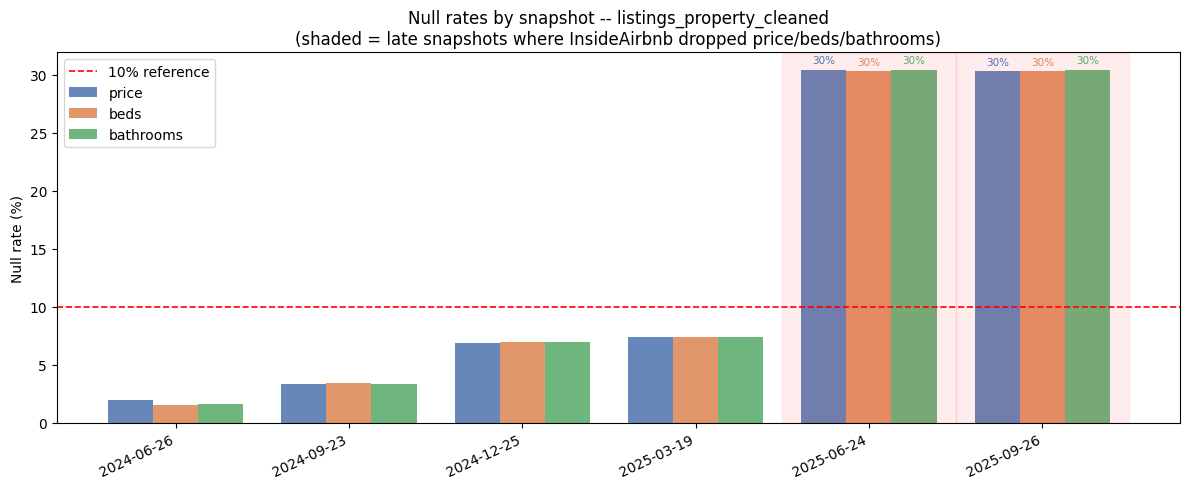

In [2]:
sql = f"""
SELECT
    snapshot_date,
    COUNT(*) AS total,
    ROUND(100.0 * SUM(CASE WHEN price     IS NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_null_price,
    ROUND(100.0 * SUM(CASE WHEN beds      IS NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_null_beds,
    ROUND(100.0 * SUM(CASE WHEN bathrooms IS NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_null_bathrooms
FROM {TABLE}
GROUP BY snapshot_date
ORDER BY snapshot_date
"""
df_null = pd.read_sql(sql, engine)
df_null['snapshot_date'] = df_null['snapshot_date'].astype(str)

# --- visualise null rates ---
snaps    = df_null['snapshot_date'].tolist()
x        = np.arange(len(snaps))
width    = 0.26
cols     = ['pct_null_price', 'pct_null_beds', 'pct_null_bathrooms']
labels   = ['price', 'beds', 'bathrooms']
palette  = ['#4C72B0', '#DD8452', '#55A868']
late_set = set(LATE)

fig, ax = plt.subplots(figsize=(12, 5))

for i, (col, lbl, clr) in enumerate(zip(cols, labels, palette)):
    vals = df_null[col].tolist()
    ax.bar(x + (i - 1) * width, vals, width, label=lbl, color=clr, alpha=0.85)
    # annotate bars for late snaps (they stand out)
    for xi, (snap, v) in enumerate(zip(snaps, vals)):
        if snap in late_set:
            ax.text(xi + (i - 1) * width, v + 0.4, f'{v:.0f}%',
                    ha='center', va='bottom', fontsize=7.5, color=clr)

ax.axhline(10, color='red', linestyle='--', linewidth=1.2, label='10% reference')
ax.set_xticks(x)
ax.set_xticklabels(snaps, rotation=25, ha='right')
ax.set_ylabel('Null rate (%)')
ax.set_title('Null rates by snapshot -- listings_property_cleaned\n'
             '(shaded = late snapshots where InsideAirbnb dropped price/beds/bathrooms)')
ax.legend()

# shade the last 2 snapshot groups
for xi, snap in enumerate(snaps):
    if snap in late_set:
        ax.axvspan(xi - 0.5, xi + 0.5, color='red', alpha=0.07)

fig.tight_layout()
plt.show()

## 2  Imputable universe -- listings in snaps 5--6 with price history in snaps 1--4

In [3]:
sql = f"""
WITH late_listings AS (
    SELECT DISTINCT listing_id, host_id
    FROM {TABLE}
    WHERE snapshot_date IN ({late_in})
),
early_priced AS (
    SELECT DISTINCT listing_id, host_id
    FROM {TABLE}
    WHERE snapshot_date IN ({early_in})
      AND price IS NOT NULL
),
early_any AS (
    SELECT DISTINCT listing_id, host_id
    FROM {TABLE}
    WHERE snapshot_date IN ({early_in})
)
SELECT
    COUNT(*)                                                                      AS total_late_listings,
    SUM(CASE WHEN ep.listing_id IS NOT NULL THEN 1 ELSE 0 END)                   AS have_price_history,
    SUM(CASE WHEN ea.listing_id IS NOT NULL
             AND ep.listing_id IS NULL THEN 1 ELSE 0 END)                        AS in_early_no_price,
    SUM(CASE WHEN ea.listing_id IS NULL THEN 1 ELSE 0 END)                       AS new_in_late_only,
    ROUND(100.0 * SUM(CASE WHEN ep.listing_id IS NOT NULL THEN 1 ELSE 0 END)
          / COUNT(*), 1)                                                          AS pct_imputable
FROM late_listings l
LEFT JOIN early_priced ep USING (listing_id, host_id)
LEFT JOIN early_any   ea USING (listing_id, host_id)
"""
pd.read_sql(sql, engine)


,total_late_listings,have_price_history,in_early_no_price,new_in_late_only,pct_imputable
0,18732,15401,119,3212,82.2


In [4]:
# Break down by each late snapshot
sql = f"""
WITH early_priced AS (
    SELECT DISTINCT listing_id, host_id
    FROM {TABLE}
    WHERE snapshot_date IN ({early_in})
      AND price IS NOT NULL
)
SELECT
    l.snapshot_date,
    COUNT(*)                                                                      AS listings,
    SUM(CASE WHEN ep.listing_id IS NOT NULL THEN 1 ELSE 0 END)                   AS imputable,
    ROUND(100.0 * SUM(CASE WHEN ep.listing_id IS NOT NULL THEN 1 ELSE 0 END)
          / COUNT(*), 1)                                                          AS pct_imputable
FROM {TABLE} l
LEFT JOIN early_priced ep USING (listing_id, host_id)
WHERE l.snapshot_date IN ({late_in})
GROUP BY l.snapshot_date
ORDER BY l.snapshot_date
"""
pd.read_sql(sql, engine)


,snapshot_date,listings,imputable,pct_imputable
0,2025-06-24,17150,15214,88.7
1,2025-09-26,16822,13950,82.9


## 3  `beds` and `bathrooms` stability across snaps 1--4

In [5]:
sql = f"""
WITH late_listings AS (
    SELECT DISTINCT listing_id, host_id
    FROM {TABLE}
    WHERE snapshot_date IN ({late_in})
),
snap_vals AS (
    SELECT p.listing_id, p.host_id, p.snapshot_date, p.beds, p.bathrooms
    FROM {TABLE} p
    INNER JOIN late_listings l USING (listing_id, host_id)
    WHERE p.snapshot_date IN ({early_in})
),
listing_stats AS (
    SELECT
        listing_id,
        COUNT(DISTINCT snapshot_date)  AS n_snaps,
        COUNT(DISTINCT beds)           AS n_distinct_beds,
        COUNT(DISTINCT bathrooms)      AS n_distinct_baths
    FROM snap_vals
    GROUP BY listing_id
    HAVING COUNT(DISTINCT snapshot_date) >= 2
)
SELECT
    n_snaps,
    COUNT(*)                                                                          AS listings,
    SUM(CASE WHEN n_distinct_beds  = 1 THEN 1 ELSE 0 END)                            AS beds_constant,
    ROUND(100.0 * SUM(CASE WHEN n_distinct_beds  = 1 THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_beds_constant,
    SUM(CASE WHEN n_distinct_baths = 1 THEN 1 ELSE 0 END)                            AS baths_constant,
    ROUND(100.0 * SUM(CASE WHEN n_distinct_baths = 1 THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_baths_constant
FROM listing_stats
GROUP BY n_snaps
ORDER BY n_snaps
"""
df_struct = pd.read_sql(sql, engine)
df_struct


,n_snaps,listings,beds_constant,pct_beds_constant,baths_constant,pct_baths_constant
0,2,1694,1564,92.3,1651,97.5
1,3,1497,1366,91.2,1443,96.4
2,4,11012,10015,90.9,10847,98.5


## 4  Price consistency (CV) across snaps 1--4

Uses **calendar price** (daily rate from calendar_cleaned), aggregated to a
per-snapshot ADR for each listing, then CV measured across those 4 snapshot ADRs.
Restricted to listings also present in snaps 5--6 (the imputable universe).

CV = stddev(snapshot_ADR) / mean(snapshot_ADR).


In [6]:
sql = f"""
WITH late_listings AS (
    SELECT DISTINCT listing_id, host_id
    FROM {TABLE}
    WHERE snapshot_date IN ({late_in})
),
snap_adr AS (
    -- Per-listing per-snapshot ADR from calendar
    SELECT c.listing_id, c.host_id, c.snapshot_date,
           AVG(c.price) AS adr
    FROM {CAL_TABLE} c
    INNER JOIN late_listings l USING (listing_id, host_id)
    WHERE c.snapshot_date IN ({early_in})
      AND c.price IS NOT NULL
    GROUP BY c.listing_id, c.host_id, c.snapshot_date
),
listing_cv AS (
    SELECT
        listing_id, host_id,
        COUNT(DISTINCT snapshot_date)                                              AS n_obs,
        ROUND(AVG(adr)::numeric, 2)                                                AS mean_adr,
        ROUND(STDDEV(adr)::numeric, 2)                                             AS std_adr,
        MIN(adr)                                                                   AS min_adr,
        MAX(adr)                                                                   AS max_adr,
        CASE WHEN AVG(adr) > 0
             THEN ROUND((COALESCE(STDDEV(adr), 0) / AVG(adr))::numeric, 4)
             ELSE 0 END                                                            AS cv
    FROM snap_adr
    GROUP BY listing_id, host_id
    HAVING COUNT(DISTINCT snapshot_date) >= 2
)
SELECT
    n_obs,
    COUNT(*)                                                                       AS listings,
    ROUND(AVG(cv)::numeric,  4)                                                    AS avg_cv,
    ROUND(PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cv)::numeric, 4)            AS p25_cv,
    ROUND(PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY cv)::numeric, 4)            AS median_cv,
    ROUND(PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cv)::numeric, 4)            AS p75_cv,
    ROUND(PERCENTILE_CONT(0.90) WITHIN GROUP (ORDER BY cv)::numeric, 4)            AS p90_cv,
    SUM(CASE WHEN cv = 0                    THEN 1 ELSE 0 END)                     AS cv_zero,
    SUM(CASE WHEN cv > 0    AND cv <= 0.05  THEN 1 ELSE 0 END)                     AS cv_le_5pct,
    SUM(CASE WHEN cv > 0.05 AND cv <= 0.15  THEN 1 ELSE 0 END)                     AS cv_5_to_15pct,
    SUM(CASE WHEN cv > 0.15 AND cv <= 0.30  THEN 1 ELSE 0 END)                     AS cv_15_to_30pct,
    SUM(CASE WHEN cv > 0.30                 THEN 1 ELSE 0 END)                     AS cv_gt_30pct
FROM listing_cv
GROUP BY n_obs
ORDER BY n_obs
"""
df_cv = pd.read_sql(sql, engine)
df_cv


,n_obs,listings,avg_cv,p25_cv,median_cv,p75_cv,p90_cv,cv_zero,cv_le_5pct,cv_5_to_15pct,cv_15_to_30pct,cv_gt_30pct
0,2,1697,0.0363,0.0,0.0,0.0,0.1059,1348,75,132,82,60
1,3,1497,0.0483,0.0,0.0,0.0,0.1467,1126,88,136,93,54
2,4,11009,0.0383,0.0,0.0,0.0,0.1350,8386,503,1119,714,287


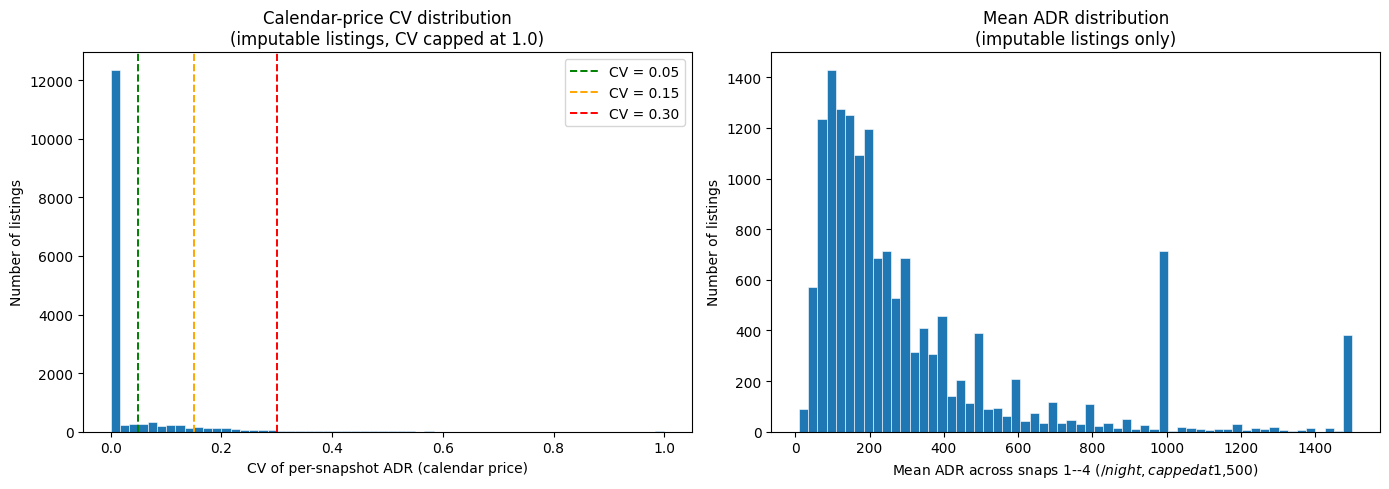

Single-obs listings (cv=0 by definition): 1,314
Multi-obs listings:                        14,202


In [7]:
# Raw per-listing CVs for visualization
sql = f"""
WITH late_listings AS (
    SELECT DISTINCT listing_id, host_id
    FROM {TABLE}
    WHERE snapshot_date IN ({late_in})
),
snap_adr AS (
    SELECT c.listing_id, c.host_id, c.snapshot_date,
           AVG(c.price) AS adr
    FROM {CAL_TABLE} c
    INNER JOIN late_listings l USING (listing_id, host_id)
    WHERE c.snapshot_date IN ({early_in})
      AND c.price IS NOT NULL
    GROUP BY c.listing_id, c.host_id, c.snapshot_date
)
SELECT
    listing_id,
    COUNT(DISTINCT snapshot_date)                                                  AS n_obs,
    ROUND(AVG(adr)::numeric, 2)                                                    AS mean_adr,
    CASE WHEN AVG(adr) > 0
         THEN ROUND((COALESCE(STDDEV(adr), 0) / AVG(adr))::numeric, 4)
         ELSE 0 END                                                                AS cv
FROM snap_adr
GROUP BY listing_id
"""
df_raw = pd.read_sql(sql, engine)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
cv_vals = df_raw['cv'].clip(upper=1.0)
ax.hist(cv_vals, bins=60, edgecolor='white', linewidth=0.4)
ax.axvline(0.05, color='green',  linestyle='--', linewidth=1.4, label='CV = 0.05')
ax.axvline(0.15, color='orange', linestyle='--', linewidth=1.4, label='CV = 0.15')
ax.axvline(0.30, color='red',    linestyle='--', linewidth=1.4, label='CV = 0.30')
ax.set_xlabel('CV of per-snapshot ADR (calendar price)')
ax.set_ylabel('Number of listings')
ax.set_title('Calendar-price CV distribution\n(imputable listings, CV capped at 1.0)')
ax.legend()

ax2 = axes[1]
ax2.hist(df_raw['mean_adr'].clip(upper=1500), bins=60, edgecolor='white', linewidth=0.4)
ax2.set_xlabel('Mean ADR across snaps 1--4 ($/night, capped at $1,500)')
ax2.set_ylabel('Number of listings')
ax2.set_title('Mean ADR distribution\n(imputable listings only)')

fig.tight_layout()
plt.show()
print(f'Single-obs listings (cv=0 by definition): {(df_raw["n_obs"]==1).sum():,}')
print(f'Multi-obs listings:                        {(df_raw["n_obs"]>=2).sum():,}')


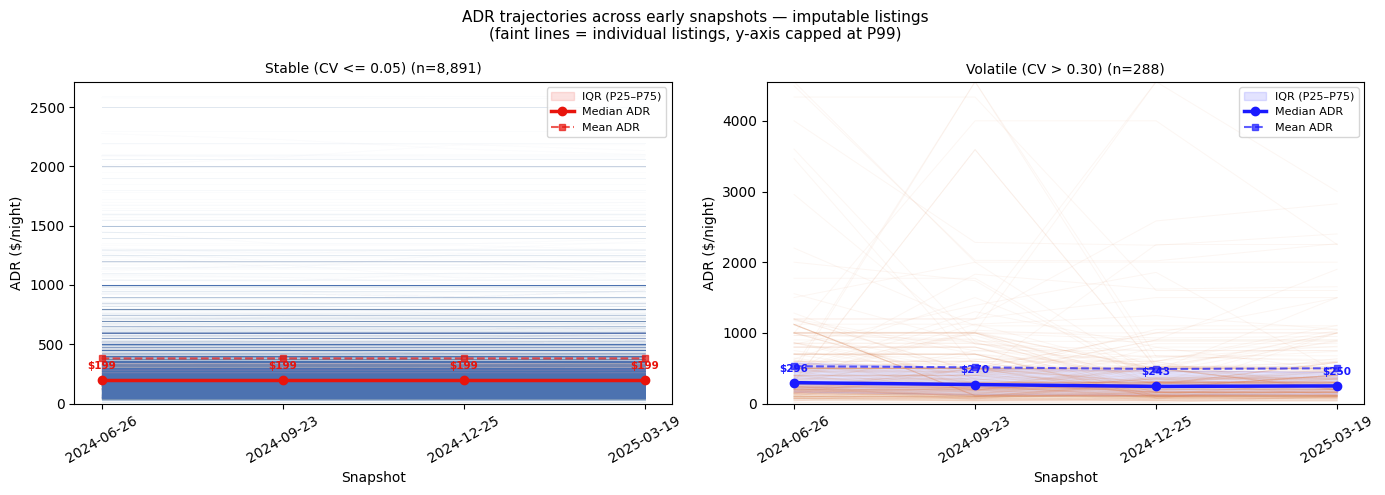

Stable   (CV <= 0.05): 8,891 listings
Volatile (CV >  0.30): 288 listings
Clipped above P99:     366 data points


In [8]:
# ADR trajectories: ALL stable vs ALL volatile listings (all 4 early snaps required)
sql = f"""
WITH late_listings AS (
    SELECT DISTINCT listing_id, host_id
    FROM {TABLE}
    WHERE snapshot_date IN ({late_in})
),
snap_adr AS (
    SELECT c.listing_id, c.host_id, c.snapshot_date,
           AVG(c.price) AS adr
    FROM {CAL_TABLE} c
    INNER JOIN late_listings l USING (listing_id, host_id)
    WHERE c.snapshot_date IN ({early_in})
      AND c.price IS NOT NULL
    GROUP BY c.listing_id, c.host_id, c.snapshot_date
),
listing_cv AS (
    SELECT listing_id,
        CASE WHEN AVG(adr) > 0
             THEN COALESCE(STDDEV(adr), 0) / AVG(adr)
             ELSE 0 END AS cv
    FROM snap_adr
    GROUP BY listing_id
    HAVING COUNT(DISTINCT snapshot_date) = 4
),
low_cv  AS (SELECT listing_id FROM listing_cv WHERE cv <= 0.05),
high_cv AS (SELECT listing_id FROM listing_cv WHERE cv >  0.30)
SELECT s.listing_id, s.snapshot_date::text AS snap, s.adr,
       CASE WHEN lc.listing_id IS NOT NULL THEN 'low_cv' ELSE 'high_cv' END AS grp
FROM snap_adr s
INNER JOIN (SELECT listing_id FROM low_cv UNION ALL SELECT listing_id FROM high_cv) u
    USING (listing_id)
LEFT JOIN low_cv lc USING (listing_id)
ORDER BY grp, s.listing_id, s.snapshot_date
"""
df_paths = pd.read_sql(sql, engine)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
group_cfg = {
    'low_cv':  dict(title='Stable (CV <= 0.05)', line_clr='#4C72B0', med_clr='#e8140c'),
    'high_cv': dict(title='Volatile (CV > 0.30)', line_clr='#DD8452', med_clr='#1a1aff'),
}

for ax, grp in zip(axes, ['low_cv', 'high_cv']):
    sub = df_paths[df_paths['grp'] == grp]
    n   = sub['listing_id'].nunique()
    cfg = group_cfg[grp]

    # Clip to 99th percentile so extreme outliers don't crush the scale
    p99 = sub['adr'].quantile(0.99)
    y_cap = max(p99 * 1.05, 50)  # small buffer above p99

    alph = max(0.02, min(0.20, 20.0 / n))

    for lid, g in sub.groupby('listing_id'):
        ax.plot(g['snap'], g['adr'].clip(upper=y_cap), color=cfg['line_clr'],
                alpha=alph, linewidth=0.7)

    # bold median + P25/P75 band
    stats = sub.groupby('snap')['adr'].agg(['median', 'mean',
        lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)]
    ).reset_index()
    stats.columns = ['snap', 'median', 'mean', 'p25', 'p75']
    stats = stats.sort_values('snap')

    ax.fill_between(stats['snap'], stats['p25'], stats['p75'],
                    color=cfg['med_clr'], alpha=0.12, label='IQR (P25–P75)')
    ax.plot(stats['snap'], stats['median'], color=cfg['med_clr'],
            linewidth=2.5, marker='o', markersize=6, label='Median ADR', zorder=5)
    ax.plot(stats['snap'], stats['mean'], color=cfg['med_clr'],
            linewidth=1.5, marker='s', markersize=4, linestyle='--',
            label='Mean ADR', zorder=5, alpha=0.7)

    ax.set_ylim(bottom=0, top=y_cap)
    ax.set_title(f"{cfg['title']} (n={n:,})", fontsize=10)
    ax.set_xlabel('Snapshot')
    ax.set_ylabel('ADR ($/night)')
    ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=8, loc='upper right')

    # annotate median values
    for _, row in stats.iterrows():
        ax.annotate(f'${row["median"]:.0f}', (row['snap'], row['median']),
                    textcoords='offset points', xytext=(0, 8),
                    ha='center', fontsize=7.5, color=cfg['med_clr'], fontweight='bold')

fig.suptitle('ADR trajectories across early snapshots — imputable listings\n'
             '(faint lines = individual listings, y-axis capped at P99)',
             fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()
print(f"Stable   (CV <= 0.05): {df_paths[df_paths['grp']=='low_cv' ]['listing_id'].nunique():,} listings")
print(f"Volatile (CV >  0.30): {df_paths[df_paths['grp']=='high_cv']['listing_id'].nunique():,} listings")
n_clipped = (df_paths['adr'] > df_paths['adr'].quantile(0.99)).sum()
print(f"Clipped above P99:     {n_clipped:,} data points")

## 5  Decision summary

In [9]:
sql = f"""
WITH late_listings AS (
    SELECT DISTINCT listing_id, host_id
    FROM {TABLE}
    WHERE snapshot_date IN ({late_in})
),
snap_adr AS (
    SELECT c.listing_id, c.host_id, c.snapshot_date,
           AVG(c.price) AS adr
    FROM {CAL_TABLE} c
    INNER JOIN late_listings l USING (listing_id, host_id)
    WHERE c.snapshot_date IN ({early_in})
      AND c.price IS NOT NULL
    GROUP BY c.listing_id, c.host_id, c.snapshot_date
),
listing_cv AS (
    SELECT
        CASE WHEN AVG(adr) > 0
             THEN COALESCE(STDDEV(adr), 0) / AVG(adr)
             ELSE 0 END AS cv
    FROM snap_adr
    GROUP BY listing_id, host_id
    HAVING COUNT(DISTINCT snapshot_date) >= 2
)
SELECT
    COUNT(*)                                                                      AS n_with_2plus_obs,
    ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cv)::numeric, 4)           AS median_cv,
    ROUND(100.0 * SUM(CASE WHEN cv <= 0.05 THEN 1 ELSE 0 END) / COUNT(*), 1)    AS pct_cv_le_5,
    ROUND(100.0 * SUM(CASE WHEN cv <= 0.15 THEN 1 ELSE 0 END) / COUNT(*), 1)    AS pct_cv_le_15,
    ROUND(100.0 * SUM(CASE WHEN cv >  0.30 THEN 1 ELSE 0 END) / COUNT(*), 1)    AS pct_cv_gt_30
FROM listing_cv
"""
df_dec = pd.read_sql(sql, engine)
print('=== Calendar-price CV summary (imputable listings with >= 2 observations) ===')
print(df_dec.to_string(index=False))
print()
print('Decision thresholds:')
print('  beds / bathrooms : impute if pct_beds_constant > 95% AND pct_baths_constant > 95%')
print('  price (ADR)      : impute if median_cv < 0.10 AND pct_cv_gt_30 < 15%')
print('                     otherwise treat as high-risk -- consider dropping or')
print('                     using mean ADR as a flagged lower-quality feature.')


=== Calendar-price CV summary (imputable listings with >= 2 observations) ===
 n_with_2plus_obs  median_cv  pct_cv_le_5  pct_cv_le_15  pct_cv_gt_30
            14203        0.0         81.2          90.9           2.8

Decision thresholds:
  beds / bathrooms : impute if pct_beds_constant > 95% AND pct_baths_constant > 95%
  price (ADR)      : impute if median_cv < 0.10 AND pct_cv_gt_30 < 15%
                     otherwise treat as high-risk -- consider dropping or
                     using mean ADR as a flagged lower-quality feature.


## 6  Write imputation table to DB

Creates `airbnb_features.listing_snapshot_imputed` -- one row per
(snapshot_date, listing_id) across all 6 snapshots.

- **adr**: actual from `overall_listing_metrics.adr_365` (snaps 1-4) or
  carried forward from the most recent non-null snapshot (snaps 5-6).

- **beds / bathrooms**: same carry-forward logic from `listings_property_cleaned`.
- **price_imputed**: TRUE only for rows in snaps 5-6 where no actual ADR exists.
- **source_snapshot**: the snapshot whose value was carried forward (NULL for actual rows).

In [10]:
# Section 6: Write imputation table to DB
sql_create = """
CREATE SCHEMA IF NOT EXISTS airbnb_features;

CREATE TABLE IF NOT EXISTS airbnb_features.listing_snapshot_imputed (
    snapshot_date   date,
    listing_id      bigint,
    host_id         bigint,
    adr             numeric(10,2),
    beds            numeric(10,2),
    bathrooms       numeric(10,2),
    price_imputed   boolean        NOT NULL DEFAULT false,
    source_snapshot date,
    PRIMARY KEY (snapshot_date, listing_id)
);

TRUNCATE airbnb_features.listing_snapshot_imputed;

INSERT INTO airbnb_features.listing_snapshot_imputed
WITH all_listings AS (
    -- All (snapshot_date, listing_id, host_id) across all 6 snapshots
    SELECT DISTINCT snapshot_date, listing_id, host_id
    FROM airbnb_cleaned.listings_property_cleaned
),
actual_adr AS (
    SELECT snapshot_date, listing_id, host_id, adr_365 AS adr
    FROM airbnb_analytics.overall_listing_metrics
    WHERE adr_365 IS NOT NULL
),
actual_struct AS (
    SELECT snapshot_date, listing_id, host_id, beds, bathrooms
    FROM airbnb_cleaned.listings_property_cleaned
    WHERE beds IS NOT NULL OR bathrooms IS NOT NULL
),
-- For each listing, carry forward from the most recent snapshot with a non-null value
latest_adr AS (
    SELECT DISTINCT ON (listing_id, host_id)
        listing_id, host_id, snapshot_date AS source_snap, adr
    FROM actual_adr
    ORDER BY listing_id, host_id, snapshot_date DESC
),
latest_struct AS (
    SELECT DISTINCT ON (listing_id, host_id)
        listing_id, host_id, snapshot_date AS source_snap, beds, bathrooms
    FROM actual_struct
    ORDER BY listing_id, host_id, snapshot_date DESC
)
SELECT
    a.snapshot_date,
    a.listing_id,
    a.host_id,
    COALESCE(act_adr.adr,     la.adr)         AS adr,
    COALESCE(act_s.beds,      ls.beds)         AS beds,
    COALESCE(act_s.bathrooms, ls.bathrooms)    AS bathrooms,
    -- price_imputed = late snapshot AND no actual ADR
    (a.snapshot_date IN ('2025-06-24', '2025-09-26')
     AND act_adr.adr IS NULL)                  AS price_imputed,
    CASE WHEN a.snapshot_date IN ('2025-06-24', '2025-09-26')
              AND act_adr.adr IS NULL
         THEN la.source_snap
         ELSE NULL
    END                                        AS source_snapshot
FROM all_listings a
LEFT JOIN actual_adr    act_adr ON act_adr.snapshot_date = a.snapshot_date
                                AND act_adr.listing_id   = a.listing_id
LEFT JOIN actual_struct act_s   ON act_s.snapshot_date   = a.snapshot_date
                                AND act_s.listing_id     = a.listing_id
LEFT JOIN latest_adr    la      ON la.listing_id = a.listing_id
                                AND la.host_id   = a.host_id
LEFT JOIN latest_struct ls      ON ls.listing_id = a.listing_id
                                AND ls.host_id   = a.host_id;
"""

with engine.begin() as conn:
    conn.execute(text(sql_create))

print("airbnb_features.listing_snapshot_imputed written successfully.")

# Verify
df_check = pd.read_sql("""
    SELECT
        snapshot_date::text,
        COUNT(*)                                                                 AS rows,
        SUM(CASE WHEN price_imputed THEN 1 ELSE 0 END)                          AS imputed_rows,
        ROUND(100.0 * AVG(CASE WHEN adr       IS NOT NULL THEN 1 ELSE 0 END), 1) AS pct_adr_filled,
        ROUND(100.0 * AVG(CASE WHEN beds      IS NOT NULL THEN 1 ELSE 0 END), 1) AS pct_beds_filled,
        ROUND(100.0 * AVG(CASE WHEN bathrooms IS NOT NULL THEN 1 ELSE 0 END), 1) AS pct_baths_filled
    FROM airbnb_features.listing_snapshot_imputed
    GROUP BY snapshot_date
    ORDER BY snapshot_date
""", engine)
df_check

airbnb_features.listing_snapshot_imputed written successfully.


,snapshot_date,rows,imputed_rows,pct_adr_filled,pct_beds_filled,pct_baths_filled
0,2024-06-26,16683,0,97.6,99.4,99.3
1,2024-09-23,16950,0,98.0,99.5,99.4
2,2024-12-25,17167,0,98.4,99.4,99.4
3,2025-03-19,17238,0,98.2,99.3,99.3
4,2025-06-24,17150,17150,87.9,97.4,97.4
5,2025-09-26,16822,16822,82.1,97.3,97.3


## 7  ADR outlier detection

Flag listings whose ADR is statistically extreme within each snapshot using two
complementary methods:

- **7a  Cross-sectional (IQR):** ADR below Q1 − 1.5×IQR or above Q3 + 1.5×IQR
  within the same snapshot.

- **7b  Temporal spikes:** For listings present in consecutive snapshots,
  |% change| in `adr_90` exceeding 50 % snapshot-over-snapshot.

=== ADR outliers (IQR method, adr_90) ===
               total  outlier_low  outlier_high  pct_outlier
snapshot_date                                               
2024-06-26     14423            0          1466         10.2
2024-09-23     14509            0          1551         10.7
2024-12-25     15973            0          1761         11.0
2025-03-19     16174            0          1747         10.8



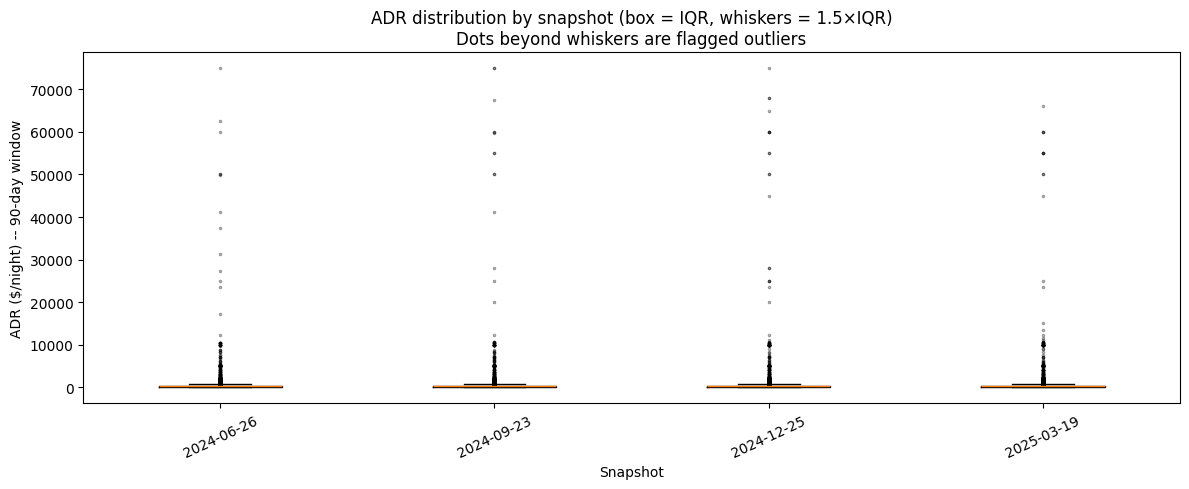

In [11]:
METRICS_TABLE = 'airbnb_analytics.overall_listing_metrics'

# --- 7a: IQR-based ADR outliers per snapshot (using adr_90) ---
sql_iqr = f"""
WITH stats AS (
    SELECT
        snapshot_date,
        PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY adr_90) AS q1,
        PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY adr_90) AS q3
    FROM {METRICS_TABLE}
    WHERE adr_90 IS NOT NULL
    GROUP BY snapshot_date
)
SELECT
    m.snapshot_date::text AS snapshot_date,
    m.listing_id,
    m.host_id,
    m.adr_90,
    s.q1, s.q3, (s.q3 - s.q1) AS iqr,
    CASE
        WHEN m.adr_90 < s.q1 - 1.5 * (s.q3 - s.q1) THEN 'low'
        WHEN m.adr_90 > s.q3 + 1.5 * (s.q3 - s.q1) THEN 'high'
        ELSE NULL
    END AS adr_outlier_dir
FROM {METRICS_TABLE} m
JOIN stats s USING (snapshot_date)
WHERE m.adr_90 IS NOT NULL
"""
df_adr = pd.read_sql(sql_iqr, engine)
df_adr_outliers = df_adr[df_adr['adr_outlier_dir'].notna()]

# Summary table
adr_summary = (
    df_adr.groupby('snapshot_date')
    .agg(
        total=('listing_id', 'count'),
        outlier_low=('adr_outlier_dir', lambda s: (s == 'low').sum()),
        outlier_high=('adr_outlier_dir', lambda s: (s == 'high').sum()),
    )
    .assign(
        pct_outlier=lambda d: round(100 * (d.outlier_low + d.outlier_high) / d.total, 1)
    )
)
print('=== ADR outliers (IQR method, adr_90) ===')
print(adr_summary.to_string())
print()

# Box plot per snapshot
snaps_sorted = sorted(df_adr['snapshot_date'].unique())
fig, ax = plt.subplots(figsize=(12, 5))
box_data = [df_adr.loc[df_adr['snapshot_date'] == s, 'adr_90'].dropna().values
            for s in snaps_sorted]
bp = ax.boxplot(box_data, tick_labels=snaps_sorted, showfliers=True,
                flierprops=dict(marker='.', markersize=3, alpha=0.4))
ax.set_ylabel('ADR ($/night) -- 90-day window')
ax.set_xlabel('Snapshot')
ax.set_title('ADR distribution by snapshot (box = IQR, whiskers = 1.5×IQR)\n'
             'Dots beyond whiskers are flagged outliers')
ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
plt.show()

=== Temporal ADR spikes (|% change| > 50%) ===
               pairs  spikes  pct_spike
snapshot_date                          
2024-09-23     12050     182        1.5
2024-12-25     13209     245        1.9
2025-03-19     14452     258        1.8



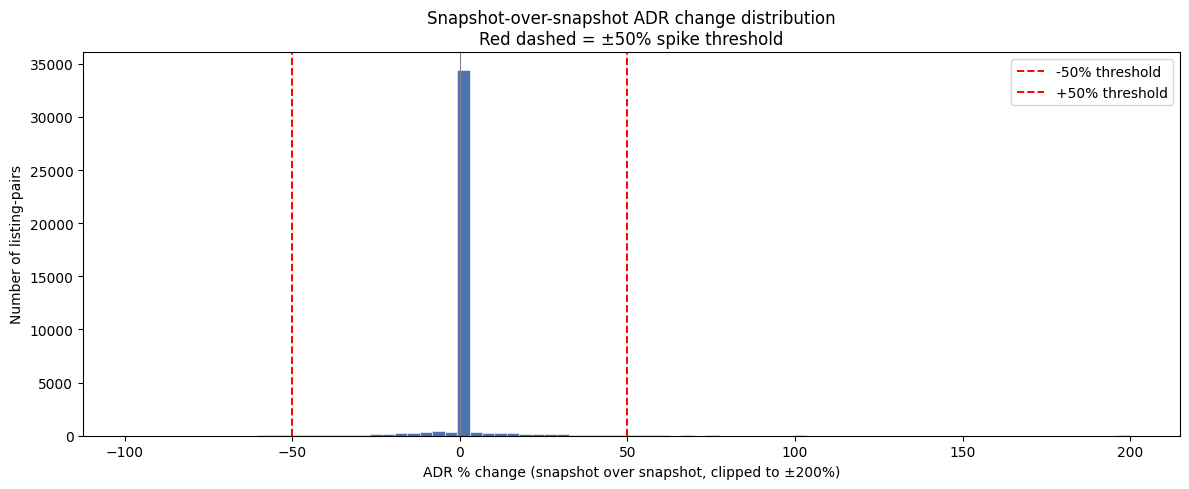

Total listing-pairs: 39,711
Spikes (|change| > 50%): 685 (1.7%)


In [12]:
# --- 7b: Temporal ADR spikes (snapshot-over-snapshot % change) ---
sql_temporal = f"""
WITH ordered AS (
    SELECT
        snapshot_date,
        listing_id,
        host_id,
        adr_90,
        LAG(adr_90) OVER (PARTITION BY listing_id ORDER BY snapshot_date) AS prev_adr_90,
        LAG(snapshot_date) OVER (PARTITION BY listing_id ORDER BY snapshot_date) AS prev_snapshot
    FROM {METRICS_TABLE}
    WHERE adr_90 IS NOT NULL
)
SELECT
    snapshot_date::text AS snapshot_date,
    listing_id,
    host_id,
    adr_90,
    prev_adr_90,
    prev_snapshot::text AS prev_snapshot,
    ROUND(((adr_90 - prev_adr_90) / NULLIF(prev_adr_90, 0) * 100)::numeric, 1) AS pct_change
FROM ordered
WHERE prev_adr_90 IS NOT NULL
"""
df_spikes = pd.read_sql(sql_temporal, engine)
df_spikes['is_spike'] = df_spikes['pct_change'].abs() > 50

spike_summary = (
    df_spikes.groupby('snapshot_date')
    .agg(
        pairs=('listing_id', 'count'),
        spikes=('is_spike', 'sum'),
    )
    .assign(pct_spike=lambda d: round(100 * d.spikes / d.pairs, 1))
)
print('=== Temporal ADR spikes (|% change| > 50%) ===')
print(spike_summary.to_string())
print()

# Histogram of % changes
fig, ax = plt.subplots(figsize=(12, 5))
clipped = df_spikes['pct_change'].clip(-200, 200)
ax.hist(clipped, bins=80, edgecolor='white', linewidth=0.4, color='#4C72B0')
ax.axvline(-50, color='red', linestyle='--', linewidth=1.4, label='-50% threshold')
ax.axvline( 50, color='red', linestyle='--', linewidth=1.4, label='+50% threshold')
ax.axvline(  0, color='grey', linestyle='-', linewidth=0.8)
ax.set_xlabel('ADR % change (snapshot over snapshot, clipped to ±200%)')
ax.set_ylabel('Number of listing-pairs')
ax.set_title('Snapshot-over-snapshot ADR change distribution\n'
             'Red dashed = ±50% spike threshold')
ax.legend()
fig.tight_layout()
plt.show()
print(f"Total listing-pairs: {len(df_spikes):,}")
print(f"Spikes (|change| > 50%): {df_spikes['is_spike'].sum():,} "
      f"({100 * df_spikes['is_spike'].mean():.1f}%)")

## 8  Occupancy anomalies

Two extremes worth flagging:

- **Saturated (occ_90 >= 0.95):** Near-100 % occupancy likely reflects a
  host-blocked calendar rather than genuine bookings.

- **Zero (occ_90 == 0 with data present):** Listing has calendar data but
  zero booked days — inactive or withdrawn from market.

=== Occupancy anomalies (90-day window) ===
               total  saturated  zero  normal  pct_saturated  pct_zero
snapshot_date                                                         
2024-06-26     16683       1126  2260   13297            6.7      13.5
2024-09-23     16950       1354  2441   13155            8.0      14.4
2024-12-25     17166       2022  1193   13951           11.8       6.9
2025-03-19     17237       1455  1063   14719            8.4       6.2
2025-06-24     17150       1591  2388   13171            9.3      13.9
2025-09-26     16822       1631  2587   12604            9.7      15.4



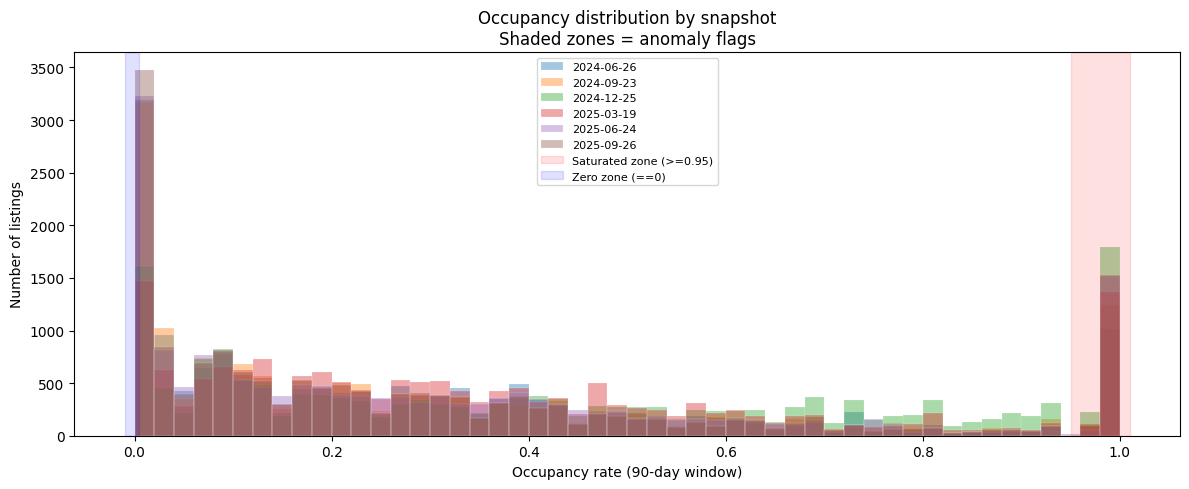

In [13]:
sql_occ = f"""
SELECT
    snapshot_date::text AS snapshot_date,
    listing_id,
    host_id,
    occ_90,
    days_90,
    booked_90,
    adr_90
FROM {METRICS_TABLE}
WHERE days_90 > 0
"""
df_occ = pd.read_sql(sql_occ, engine)
df_occ['occ_flag'] = np.where(
    df_occ['occ_90'] >= 0.95, 'saturated',
    np.where(df_occ['occ_90'] == 0, 'zero', 'normal'))

occ_summary = (
    df_occ.groupby('snapshot_date')
    .agg(
        total=('listing_id', 'count'),
        saturated=('occ_flag', lambda s: (s == 'saturated').sum()),
        zero=('occ_flag', lambda s: (s == 'zero').sum()),
        normal=('occ_flag', lambda s: (s == 'normal').sum()),
    )
    .assign(
        pct_saturated=lambda d: round(100 * d.saturated / d.total, 1),
        pct_zero=lambda d: round(100 * d.zero / d.total, 1),
    )
)
print('=== Occupancy anomalies (90-day window) ===')
print(occ_summary.to_string())
print()

# Occupancy distribution with anomaly zones
fig, ax = plt.subplots(figsize=(12, 5))
for snap in sorted(df_occ['snapshot_date'].unique()):
    vals = df_occ.loc[df_occ['snapshot_date'] == snap, 'occ_90'].dropna()
    ax.hist(vals, bins=50, alpha=0.4, label=snap, edgecolor='white', linewidth=0.3)

ax.axvspan(0.95, 1.01, color='red', alpha=0.12, label='Saturated zone (>=0.95)')
ax.axvspan(-0.01, 0.005, color='blue', alpha=0.12, label='Zero zone (==0)')
ax.set_xlabel('Occupancy rate (90-day window)')
ax.set_ylabel('Number of listings')
ax.set_title('Occupancy distribution by snapshot\n'
             'Shaded zones = anomaly flags')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 8b  Refining occupancy flags: hotels and new listings

Not all extremes are anomalies:

- **Saturated (occ >= 0.95)** could be **hotels or professional hospitality**
  properties that legitimately run near capacity.

- **Zero occupancy** could be **brand-new listings** that haven't launched yet
  (no first review = never booked).

Cross-reference with `property_type`, `room_type`, and `first_review_date`
from `listings_property_cleaned` to separate legitimate cases from true
anomalies, then update the flag definitions.

=== Saturated occupancy (>= 0.95) breakdown ===
               total_saturated  hotel_like  non_hotel  pct_hotel
snapshot_date                                                   
2024-06-26                1126          48       1078        4.3
2024-09-23                1354          64       1290        4.7
2024-12-25                2022         121       1901        6.0
2025-03-19                1455          94       1361        6.5
2025-06-24                1591         119       1472        7.5
2025-09-26                1631         137       1494        8.4

Top property_types among saturated-occupancy listings:
  entire rental unit                       2,660
  entire home                              2,371
  entire condo                             1,239
  private room in home                       771
  room in hotel                              291 ← hotel-like
  entire serviced apartment                  281
  entire villa                               201
  entire guesthouse 

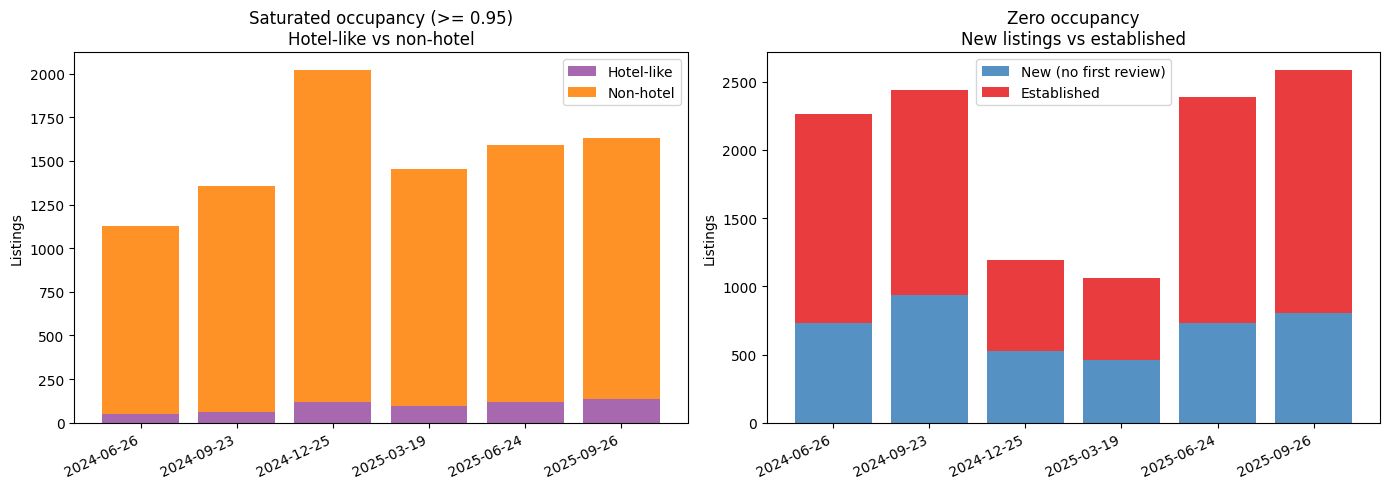


Refined flag definitions:
  flag_occ_saturated: occ_90 >= 0.95 AND NOT hotel-like property
  flag_occ_zero:      occ_90 == 0     AND has first_review (not brand-new)


In [14]:
# --- 8b: Break down saturated & zero-occ by property type and listing age ---
sql_enrich = f"""
SELECT
    m.snapshot_date::text AS snapshot_date,
    m.listing_id,
    m.occ_90,
    m.days_90,
    p.property_type,
    p.room_type,
    p.first_review_date
FROM {METRICS_TABLE} m
JOIN {TABLE} p
    ON p.snapshot_date = m.snapshot_date AND p.listing_id = m.listing_id
WHERE m.days_90 > 0
"""
df_enrich = pd.read_sql(sql_enrich, engine)

# Classify property types as hotel-like
hotel_keywords = ['hotel', 'hostel', 'motel', 'resort', 'apart-hotel', 'aparthotel',
                  'boutique hotel', 'bed and breakfast']
df_enrich['is_hotel_like'] = (
    df_enrich['property_type'].str.contains('|'.join(hotel_keywords), case=False, na=False) |
    df_enrich['room_type'].str.contains('hotel', case=False, na=False)
)

# Classify new listings (no first_review = never booked)
df_enrich['is_new_listing'] = df_enrich['first_review_date'].isna()

# --- Saturated breakdown ---
saturated = df_enrich[df_enrich['occ_90'] >= 0.95]
sat_breakdown = (
    saturated.groupby('snapshot_date')
    .agg(
        total_saturated=('listing_id', 'count'),
        hotel_like=('is_hotel_like', 'sum'),
        non_hotel=('is_hotel_like', lambda s: (~s).sum()),
    )
    .assign(
        pct_hotel=lambda d: round(100 * d.hotel_like / d.total_saturated, 1),
    )
)
print('=== Saturated occupancy (>= 0.95) breakdown ===')
print(sat_breakdown.to_string())
print()

# Top property_types among saturated
sat_types = (
    saturated.groupby('property_type')['listing_id'].count()
    .sort_values(ascending=False).head(15)
)
print('Top property_types among saturated-occupancy listings:')
for pt, cnt in sat_types.items():
    hotel_tag = ' ← hotel-like' if any(kw in str(pt).lower() for kw in hotel_keywords) else ''
    print(f"  {pt:40s} {cnt:>5,}{hotel_tag}")

print()

# --- Zero-occ breakdown ---
zero_occ = df_enrich[(df_enrich['occ_90'] == 0) | (df_enrich['occ_90'].isna() & (df_enrich['days_90'] > 0))]
zero_breakdown = (
    zero_occ.groupby('snapshot_date')
    .agg(
        total_zero=('listing_id', 'count'),
        new_listing=('is_new_listing', 'sum'),
        established=('is_new_listing', lambda s: (~s).sum()),
    )
    .assign(
        pct_new=lambda d: round(100 * d.new_listing / d.total_zero, 1),
    )
)
print('=== Zero occupancy breakdown ===')
print(zero_breakdown.to_string())
print()

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: saturated — hotel vs non-hotel
ax = axes[0]
snaps = sat_breakdown.index.tolist()
x = np.arange(len(snaps))
ax.bar(x, sat_breakdown['hotel_like'], label='Hotel-like', color='#984ea3', alpha=0.85)
ax.bar(x, sat_breakdown['non_hotel'], bottom=sat_breakdown['hotel_like'],
       label='Non-hotel', color='#ff7f00', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(snaps, rotation=25, ha='right')
ax.set_ylabel('Listings')
ax.set_title('Saturated occupancy (>= 0.95)\nHotel-like vs non-hotel')
ax.legend()

# Right: zero-occ — new vs established
ax2 = axes[1]
snaps2 = zero_breakdown.index.tolist()
x2 = np.arange(len(snaps2))
ax2.bar(x2, zero_breakdown['new_listing'], label='New (no first review)', color='#377eb8', alpha=0.85)
ax2.bar(x2, zero_breakdown['established'], bottom=zero_breakdown['new_listing'],
        label='Established', color='#e41a1c', alpha=0.85)
ax2.set_xticks(x2)
ax2.set_xticklabels(snaps2, rotation=25, ha='right')
ax2.set_ylabel('Listings')
ax2.set_title('Zero occupancy\nNew listings vs established')
ax2.legend()

fig.tight_layout()
plt.show()

print(f"\nRefined flag definitions:")
print(f"  flag_occ_saturated: occ_90 >= 0.95 AND NOT hotel-like property")
print(f"  flag_occ_zero:      occ_90 == 0     AND has first_review (not brand-new)")

## 9  Data gap analysis

Three dimensions of data completeness:

- **9a  Calendar coverage:** Ratio of actual calendar rows to 365 expected days.
  Listings below 80 % coverage are flagged — metrics built on sparse data are
  unreliable.

- **9b  Missing price on booked days:** Booked (`available = 0`) but `price IS NULL`.
  ADR / RevPAR are understated when booked-day prices are missing.

- **9c  Listing churn:** Listings that appear or disappear across snapshots.
  Churn complicates longitudinal analysis and imputation.

=== Calendar coverage (rows / 365 expected) ===
               listings  median_coverage  low_cov_count  pct_low_cov
snapshot_date                                                       
2024-06-26        16683              1.0              0          0.0
2024-09-23        16950              1.0              0          0.0
2024-12-25        17166              1.0              0          0.0
2025-03-19        17237              1.0              0          0.0
2025-06-24        17150              1.0              0          0.0
2025-09-26        16822              1.0              0          0.0



=== Missing price on booked days (>20% threshold) ===
               listings_with_bookings  median_pct_missing  flagged  pct_flagged
snapshot_date                                                                  
2024-06-26                      15904                 0.0        0          0.0
2024-09-23                      16166                 0.0        0          0.0
2024-12-25                      16648                 0.0        0          0.0
2025-03-19                      16653                 0.0        0          0.0
2025-06-24                      16039               100.0    16039        100.0
2025-09-26                      15696               100.0    15696        100.0



=== Listing presence across 6 snapshots ===
  Present in 1/6 snapshots: 4,969 listings
  Present in 2/6 snapshots: 3,733 listings
  Present in 3/6 snapshots: 2,495 listings
  Present in 4/6 snapshots: 2,650 listings
  Present in 5/6 snapshots: 2,130 listings
  Present in 6/6 snapshots: 10,140 listings

  Churned (missing from >= 1 snapshot): 15,977 / 26,117 (61.2%)


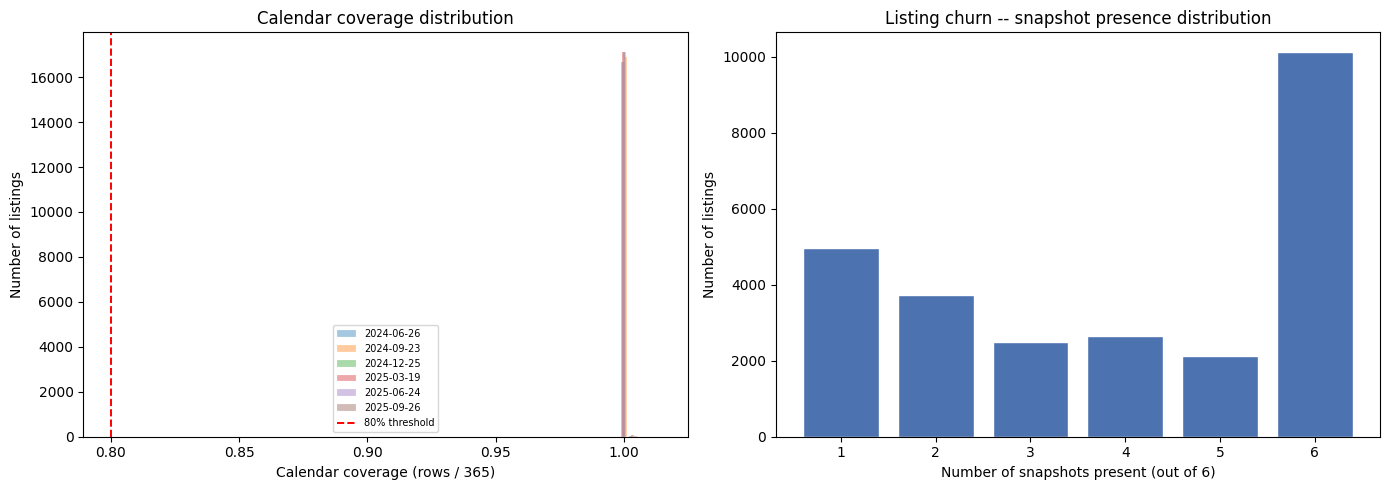

In [15]:
# --- 9a: Calendar coverage per listing per snapshot ---
sql_cov = f"""
SELECT
    snapshot_date::text AS snapshot_date,
    listing_id,
    host_id,
    COUNT(*) AS cal_rows,
    ROUND(COUNT(*)::numeric / 365, 3) AS coverage
FROM {CAL_TABLE}
GROUP BY snapshot_date, listing_id, host_id
"""
df_cov = pd.read_sql(sql_cov, engine)
df_cov['low_coverage'] = df_cov['coverage'] < 0.80

cov_summary = (
    df_cov.groupby('snapshot_date')
    .agg(
        listings=('listing_id', 'count'),
        median_coverage=('coverage', 'median'),
        low_cov_count=('low_coverage', 'sum'),
    )
    .assign(pct_low_cov=lambda d: round(100 * d.low_cov_count / d.listings, 1))
)
print('=== Calendar coverage (rows / 365 expected) ===')
print(cov_summary.to_string())
print()

# --- 9b: Missing price on booked days ---
sql_price_gap = f"""
SELECT
    snapshot_date::text AS snapshot_date,
    listing_id,
    host_id,
    SUM(CASE WHEN available = 0 THEN 1 ELSE 0 END) AS booked_days,
    SUM(CASE WHEN available = 0 AND price IS NULL THEN 1 ELSE 0 END) AS booked_no_price
FROM {CAL_TABLE}
GROUP BY snapshot_date, listing_id, host_id
HAVING SUM(CASE WHEN available = 0 THEN 1 ELSE 0 END) > 0
"""
df_pgap = pd.read_sql(sql_price_gap, engine)
df_pgap['pct_missing'] = round(100 * df_pgap['booked_no_price'] / df_pgap['booked_days'], 1)
df_pgap['flag_missing_price'] = df_pgap['pct_missing'] > 20

pgap_summary = (
    df_pgap.groupby('snapshot_date')
    .agg(
        listings_with_bookings=('listing_id', 'count'),
        median_pct_missing=('pct_missing', 'median'),
        flagged=('flag_missing_price', 'sum'),
    )
    .assign(pct_flagged=lambda d: round(100 * d.flagged / d.listings_with_bookings, 1))
)
print('=== Missing price on booked days (>20% threshold) ===')
print(pgap_summary.to_string())
print()

# --- 9c: Listing churn ---
sql_churn = f"""
SELECT listing_id, host_id,
       array_agg(DISTINCT snapshot_date::text ORDER BY snapshot_date::text) AS present_in
FROM {TABLE}
GROUP BY listing_id, host_id
"""
df_churn = pd.read_sql(sql_churn, engine)
all_snaps = sorted(df_churn['present_in'].explode().unique())
df_churn['n_snaps'] = df_churn['present_in'].apply(len)
df_churn['is_churned'] = df_churn['n_snaps'] < len(all_snaps)

churn_dist = df_churn['n_snaps'].value_counts().sort_index()
print(f'=== Listing presence across {len(all_snaps)} snapshots ===')
for n, cnt in churn_dist.items():
    print(f"  Present in {n}/{len(all_snaps)} snapshots: {cnt:,} listings")
print(f"\n  Churned (missing from >= 1 snapshot): {df_churn['is_churned'].sum():,} "
      f"/ {len(df_churn):,} ({100*df_churn['is_churned'].mean():.1f}%)")

# Visualization: coverage + churn side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for snap in sorted(df_cov['snapshot_date'].unique()):
    vals = df_cov.loc[df_cov['snapshot_date'] == snap, 'coverage'].clip(upper=1.5)
    ax.hist(vals, bins=50, alpha=0.4, label=snap, edgecolor='white', linewidth=0.3)
ax.axvline(0.80, color='red', linestyle='--', linewidth=1.4, label='80% threshold')
ax.set_xlabel('Calendar coverage (rows / 365)')
ax.set_ylabel('Number of listings')
ax.set_title('Calendar coverage distribution')
ax.legend(fontsize=7)

ax2 = axes[1]
ax2.bar(churn_dist.index, churn_dist.values, color='#4C72B0', edgecolor='white')
ax2.set_xlabel(f'Number of snapshots present (out of {len(all_snaps)})')
ax2.set_ylabel('Number of listings')
ax2.set_title('Listing churn -- snapshot presence distribution')

fig.tight_layout()
plt.show()

## 10  Combined quality flags → `airbnb_features.listing_quality_flags`

Materialise a single boolean-flag table combining all anomaly detections above.
One row per (snapshot_date, listing_id).  Downstream consumers can filter or
weight listings by flag status.

| Flag | Source | Threshold |
|------|--------|-----------|
| `flag_adr_outlier` | §7a IQR | ADR outside Q1−1.5×IQR … Q3+1.5×IQR |
| `flag_adr_spike` | §7b temporal | \|Δ ADR %\| > 50 % vs. previous snapshot |
| `flag_occ_saturated` | §8 + §8b | occ_90 >= 0.95 **AND NOT hotel-like** property |
| `flag_occ_zero` | §8 + §8b | occ_90 == 0 with data present **AND has first_review** (not brand-new) |
| `flag_low_coverage` | §9a | calendar rows / 365 < 0.80 |

airbnb_features.listing_quality_flags written successfully (refined flags).

snapshot_date  listings  adr_outlier  adr_spike  occ_saturated  occ_zero  low_coverage  any_flag
   2024-06-26     16683         1466          0           1078      1531             0      4011
   2024-09-23     16950         1551        182           1290      1503             0      4412
   2024-12-25     17166         1761        245           1901       668             0      4383
   2025-03-19     17237         1747        258           1361       603             0      3844
   2025-06-24     17150            0          0           1472      1660             0      3132
   2025-09-26     16822            0          0           1494      1784             0      3278


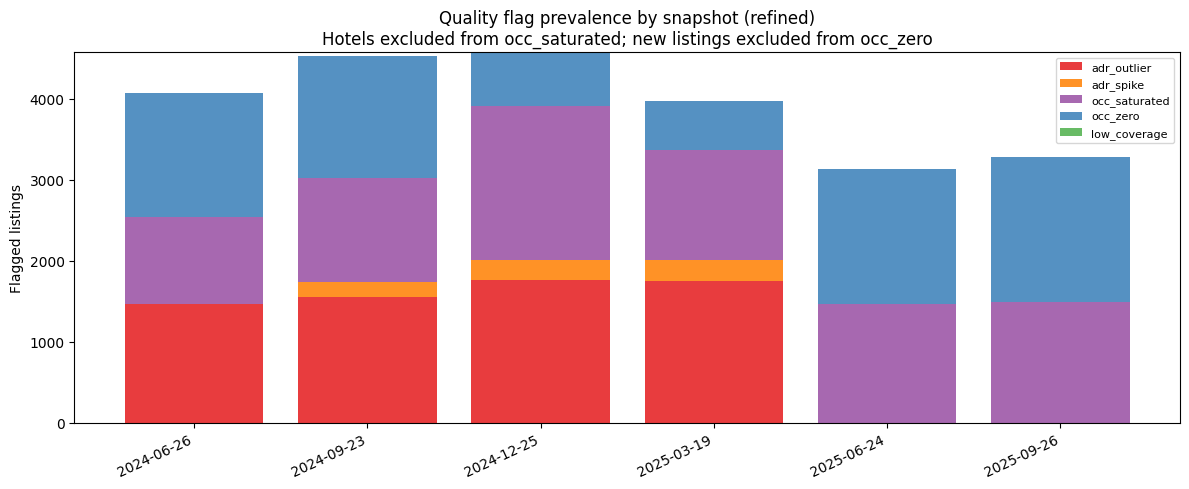

In [16]:
sql_flags = f"""
CREATE SCHEMA IF NOT EXISTS airbnb_features;

DROP TABLE IF EXISTS airbnb_features.listing_quality_flags;

CREATE TABLE airbnb_features.listing_quality_flags AS
WITH
-- Base population: all listing-snapshots from metrics
base AS (
    SELECT snapshot_date, listing_id, host_id,
           adr_90, occ_90, days_90
    FROM {METRICS_TABLE}
),
-- Property attributes for occupancy flag refinement
prop AS (
    SELECT snapshot_date, listing_id,
           property_type, room_type, first_review_date
    FROM {TABLE}
),
-- 7a: IQR-based ADR outliers
iqr_stats AS (
    SELECT snapshot_date,
           PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY adr_90) AS q1,
           PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY adr_90) AS q3
    FROM {METRICS_TABLE}
    WHERE adr_90 IS NOT NULL
    GROUP BY snapshot_date
),
adr_outliers AS (
    SELECT m.snapshot_date, m.listing_id,
           (m.adr_90 < s.q1 - 1.5 * (s.q3 - s.q1)
            OR m.adr_90 > s.q3 + 1.5 * (s.q3 - s.q1)) AS flag_adr_outlier
    FROM {METRICS_TABLE} m
    JOIN iqr_stats s USING (snapshot_date)
    WHERE m.adr_90 IS NOT NULL
),
-- 7b: Temporal ADR spikes
adr_changes AS (
    SELECT snapshot_date, listing_id,
           adr_90,
           LAG(adr_90) OVER (PARTITION BY listing_id ORDER BY snapshot_date) AS prev_adr
    FROM {METRICS_TABLE}
    WHERE adr_90 IS NOT NULL
),
adr_spikes AS (
    SELECT snapshot_date, listing_id,
           (ABS(adr_90 - prev_adr) / NULLIF(prev_adr, 0) > 0.50) AS flag_adr_spike
    FROM adr_changes
    WHERE prev_adr IS NOT NULL
),
-- 9a: Calendar coverage
cal_coverage AS (
    SELECT snapshot_date, listing_id,
           COUNT(*)::numeric / 365 AS coverage
    FROM {CAL_TABLE}
    GROUP BY snapshot_date, listing_id
)
SELECT
    b.snapshot_date,
    b.listing_id,
    b.host_id,
    COALESCE(ao.flag_adr_outlier, false)                       AS flag_adr_outlier,
    COALESCE(asp.flag_adr_spike, false)                        AS flag_adr_spike,
    -- Saturated: occ >= 0.95 AND NOT hotel-like property
    (b.occ_90 IS NOT NULL AND b.occ_90 >= 0.95
     AND NOT (
         COALESCE(p.property_type, '') ~* '(hotel|hostel|motel|resort|apart-hotel|aparthotel|bed and breakfast)'
         OR COALESCE(p.room_type, '') ~* 'hotel'
     ))                                                        AS flag_occ_saturated,
    -- Zero: occ == 0 AND has first_review (not brand-new unlaunched listing)
    (b.days_90 > 0 AND COALESCE(b.occ_90, 0) = 0
     AND p.first_review_date IS NOT NULL)                      AS flag_occ_zero,
    COALESCE(cc.coverage < 0.80, false)                        AS flag_low_coverage
FROM base b
LEFT JOIN prop         p   ON p.snapshot_date  = b.snapshot_date
                           AND p.listing_id    = b.listing_id
LEFT JOIN adr_outliers ao  ON ao.snapshot_date = b.snapshot_date
                           AND ao.listing_id   = b.listing_id
LEFT JOIN adr_spikes   asp ON asp.snapshot_date = b.snapshot_date
                           AND asp.listing_id   = b.listing_id
LEFT JOIN cal_coverage cc  ON cc.snapshot_date  = b.snapshot_date
                           AND cc.listing_id    = b.listing_id;

ALTER TABLE airbnb_features.listing_quality_flags
    ADD PRIMARY KEY (snapshot_date, listing_id);

CREATE INDEX IF NOT EXISTS ix_quality_flags_host
    ON airbnb_features.listing_quality_flags (host_id);

ANALYZE airbnb_features.listing_quality_flags;
"""

with engine.begin() as conn:
    conn.execute(text(sql_flags))

print("airbnb_features.listing_quality_flags written successfully (refined flags).")

# --- Verification & summary ---
df_flags = pd.read_sql("""
    SELECT
        snapshot_date::text,
        COUNT(*) AS listings,
        SUM(flag_adr_outlier::int)    AS adr_outlier,
        SUM(flag_adr_spike::int)      AS adr_spike,
        SUM(flag_occ_saturated::int)  AS occ_saturated,
        SUM(flag_occ_zero::int)       AS occ_zero,
        SUM(flag_low_coverage::int)   AS low_coverage,
        SUM(CASE WHEN flag_adr_outlier OR flag_adr_spike OR flag_occ_saturated
                      OR flag_occ_zero OR flag_low_coverage
                 THEN 1 ELSE 0 END)   AS any_flag
    FROM airbnb_features.listing_quality_flags
    GROUP BY snapshot_date
    ORDER BY snapshot_date
""", engine)
print()
print(df_flags.to_string(index=False))

# Stacked bar: flag prevalence per snapshot
flag_cols = ['adr_outlier', 'adr_spike', 'occ_saturated',
             'occ_zero', 'low_coverage']
flag_colors = ['#e41a1c', '#ff7f00', '#984ea3', '#377eb8', '#4daf4a']

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(df_flags))
bottom = np.zeros(len(df_flags))
for col, clr in zip(flag_cols, flag_colors):
    vals = df_flags[col].values.astype(float)
    ax.bar(x, vals, bottom=bottom, label=col, color=clr, alpha=0.85)
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(df_flags['snapshot_date'], rotation=25, ha='right')
ax.set_ylabel('Flagged listings')
ax.set_title('Quality flag prevalence by snapshot (refined)\n'
             'Hotels excluded from occ_saturated; new listings excluded from occ_zero')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 11  Impact analysis: all listings vs. clean (unflagged) subset

Join metrics with `listing_quality_flags` and compare key distributional
statistics — ADR, occupancy, RevPAR — across cohorts.  **Restricted to the
4 early snapshots** (2024-06-26 … 2025-03-19) where ADR is actual, not
carry-forward.

| Cohort | Definition |
|--------|------------|
| **All** | Every listing-snapshot with actual ADR |
| **Clean** | Rows where **no** quality flag is TRUE |
| **Flagged** | Rows with at least one flag |

If the flags are catching real noise, we expect the clean subset to have
tighter distributions (lower std, narrower IQR) and potentially different
central tendency (lower mean ADR if luxury outliers removed; higher mean
occupancy if zero-occ listings removed).

=== Distributional comparison: All vs Clean vs Flagged ===
snapshot_date  cohort       n  mean_adr  median_adr  std_adr  p25_adr  p75_adr  mean_occ  median_occ  mean_revpar  median_revpar
   2024-06-26     all 14423.0    383.03       199.0  1498.12    120.0    351.0     0.332        0.26       126.58          52.27
   2024-06-26   clean 11943.0    220.41       184.0   140.08    112.0    299.0     0.279        0.23        63.38          39.00
   2024-06-26 flagged  2480.0   1166.15       799.0  3495.93    198.0   1000.0     0.588        0.56       430.96         201.58
   2024-09-23     all 14509.0    400.09       199.0  1803.32    119.0    350.0     0.342        0.24       122.44          51.11
   2024-09-23   clean 11600.0    217.06       180.0   137.55    110.0    295.0     0.280        0.21        60.23          37.80
   2024-09-23 flagged  2909.0   1129.95       725.0  3934.71    165.0   1000.0     0.591        0.56       370.51         180.00
   2024-12-25     all 15973.0    417.8

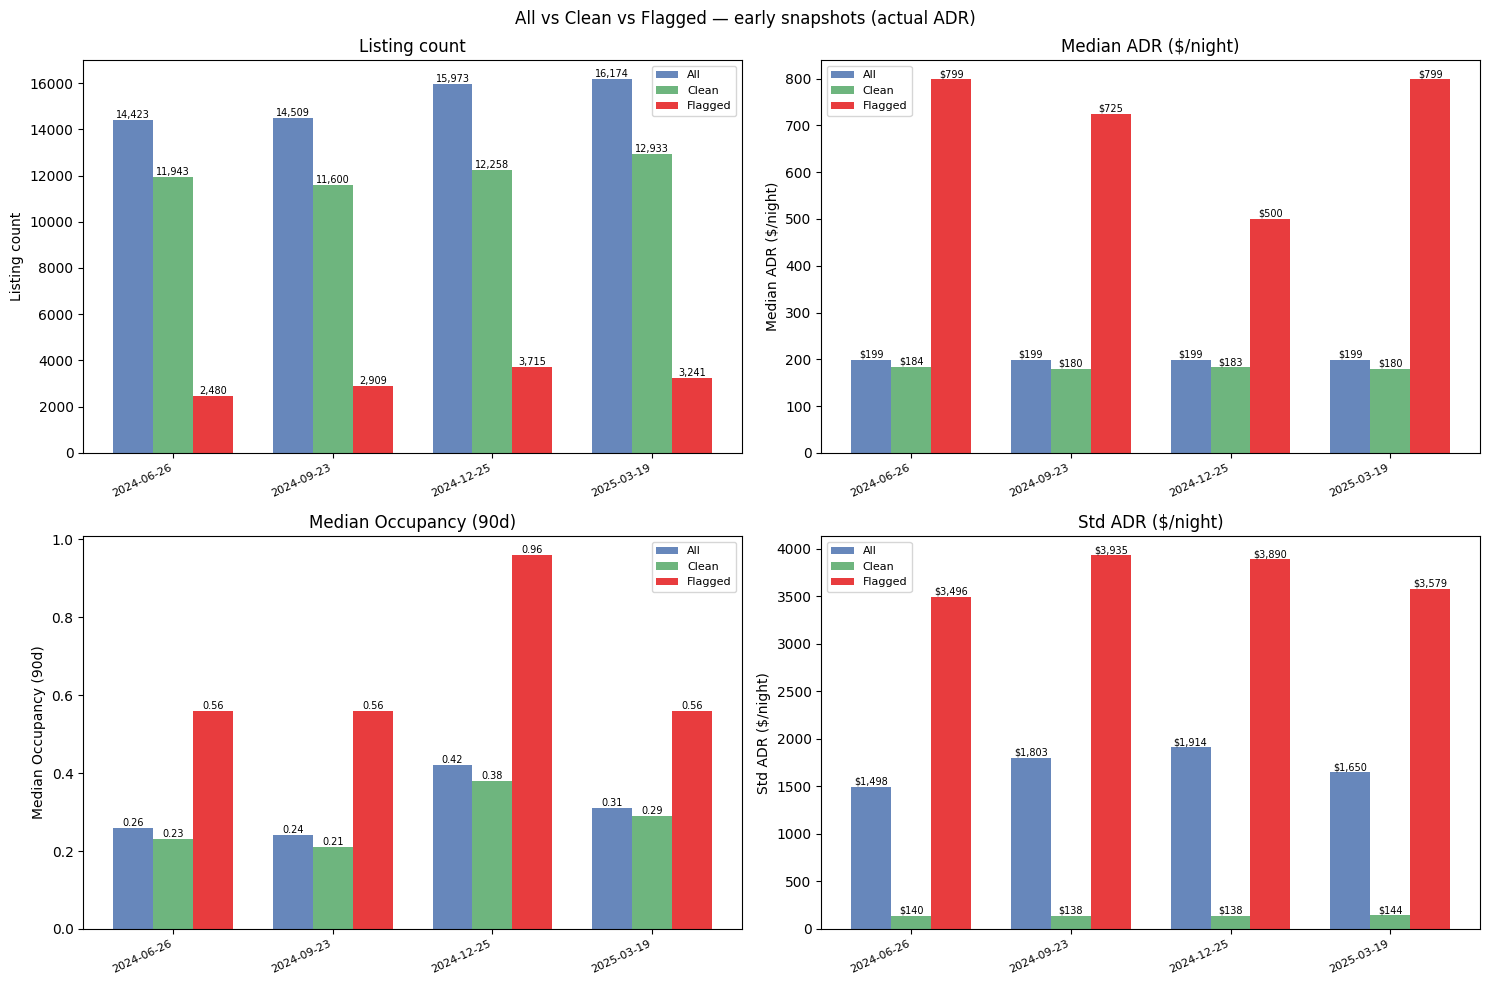

In [17]:
FLAGS_TABLE = 'airbnb_features.listing_quality_flags'

# Pull actual metrics + flags (early snapshots only — no imputation involved)
sql_compare = f"""
SELECT
    m.snapshot_date::text AS snapshot_date,
    m.listing_id,
    m.adr_90  AS adr,
    m.occ_90,
    m.revpar_90,
    COALESCE(f.flag_adr_outlier,   false) AS flag_adr_outlier,
    COALESCE(f.flag_adr_spike,     false) AS flag_adr_spike,
    COALESCE(f.flag_occ_saturated, false) AS flag_occ_saturated,
    COALESCE(f.flag_occ_zero,      false) AS flag_occ_zero,
    COALESCE(f.flag_low_coverage,  false) AS flag_low_coverage
FROM {METRICS_TABLE} m
LEFT JOIN {FLAGS_TABLE} f
    ON f.snapshot_date = m.snapshot_date AND f.listing_id = m.listing_id
WHERE m.adr_90 IS NOT NULL
"""
df = pd.read_sql(sql_compare, engine)

df['any_flag'] = (
    df['flag_adr_outlier'] | df['flag_adr_spike'] |
    df['flag_occ_saturated'] | df['flag_occ_zero'] |
    df['flag_low_coverage']
)
df['cohort'] = np.where(df['any_flag'], 'flagged', 'clean')

# --- Per-snapshot summary stats: All vs Clean vs Flagged ---
def cohort_stats(group):
    return pd.Series({
        'n':          len(group),
        'mean_adr':   round(group['adr'].mean(), 2),
        'median_adr': round(group['adr'].median(), 2),
        'std_adr':    round(group['adr'].std(), 2),
        'p25_adr':    round(group['adr'].quantile(0.25), 2),
        'p75_adr':    round(group['adr'].quantile(0.75), 2),
        'mean_occ':   round(group['occ_90'].mean(), 3) if group['occ_90'].notna().any() else None,
        'median_occ': round(group['occ_90'].median(), 3) if group['occ_90'].notna().any() else None,
        'mean_revpar':   round(group['revpar_90'].mean(), 2) if group['revpar_90'].notna().any() else None,
        'median_revpar': round(group['revpar_90'].median(), 2) if group['revpar_90'].notna().any() else None,
    })

stats_all     = df.groupby('snapshot_date').apply(cohort_stats, include_groups=False).reset_index()
stats_all.insert(1, 'cohort', 'all')
stats_clean   = df[~df['any_flag']].groupby('snapshot_date').apply(cohort_stats, include_groups=False).reset_index()
stats_clean.insert(1, 'cohort', 'clean')
stats_flagged = df[df['any_flag']].groupby('snapshot_date').apply(cohort_stats, include_groups=False).reset_index()
stats_flagged.insert(1, 'cohort', 'flagged')

df_stats = pd.concat([stats_all, stats_clean, stats_flagged], ignore_index=True)
df_stats = df_stats.sort_values(['snapshot_date', 'cohort']).reset_index(drop=True)

print('=== Distributional comparison: All vs Clean vs Flagged ===')
print(df_stats.to_string(index=False))

# --- Bar charts: cohort counts + key metrics per snapshot ---
snaps = sorted(df_stats['snapshot_date'].unique())
x = np.arange(len(snaps))
width = 0.25
cohorts = ['all', 'clean', 'flagged']
cohort_colors = {'all': '#4C72B0', 'clean': '#55A868', 'flagged': '#e41a1c'}

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

chart_cfg = [
    ('n',          'Listing count',         axes[0, 0]),
    ('median_adr', 'Median ADR ($/night)',   axes[0, 1]),
    ('median_occ', 'Median Occupancy (90d)', axes[1, 0]),
    ('std_adr',    'Std ADR ($/night)',      axes[1, 1]),
]

for metric, ylabel, ax in chart_cfg:
    for i, cohort in enumerate(cohorts):
        vals = df_stats.loc[df_stats['cohort'] == cohort].set_index('snapshot_date').reindex(snaps)[metric].values
        bars = ax.bar(x + (i - 1) * width, vals.astype(float), width,
                      label=cohort.capitalize(), color=cohort_colors[cohort], alpha=0.85)
        # annotate bars
        for xi, v in enumerate(vals):
            if not np.isnan(float(v)):
                fmt = f'{int(v):,}' if metric == 'n' else (f'{float(v):.2f}' if metric == 'median_occ' else f'${float(v):,.0f}')
                ax.text(xi + (i - 1) * width, float(v), fmt,
                        ha='center', va='bottom', fontsize=7, rotation=0)

    ax.set_xticks(x)
    ax.set_xticklabels(snaps, rotation=25, ha='right', fontsize=8)
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.legend(fontsize=8)

fig.suptitle('All vs Clean vs Flagged — early snapshots (actual ADR)', fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

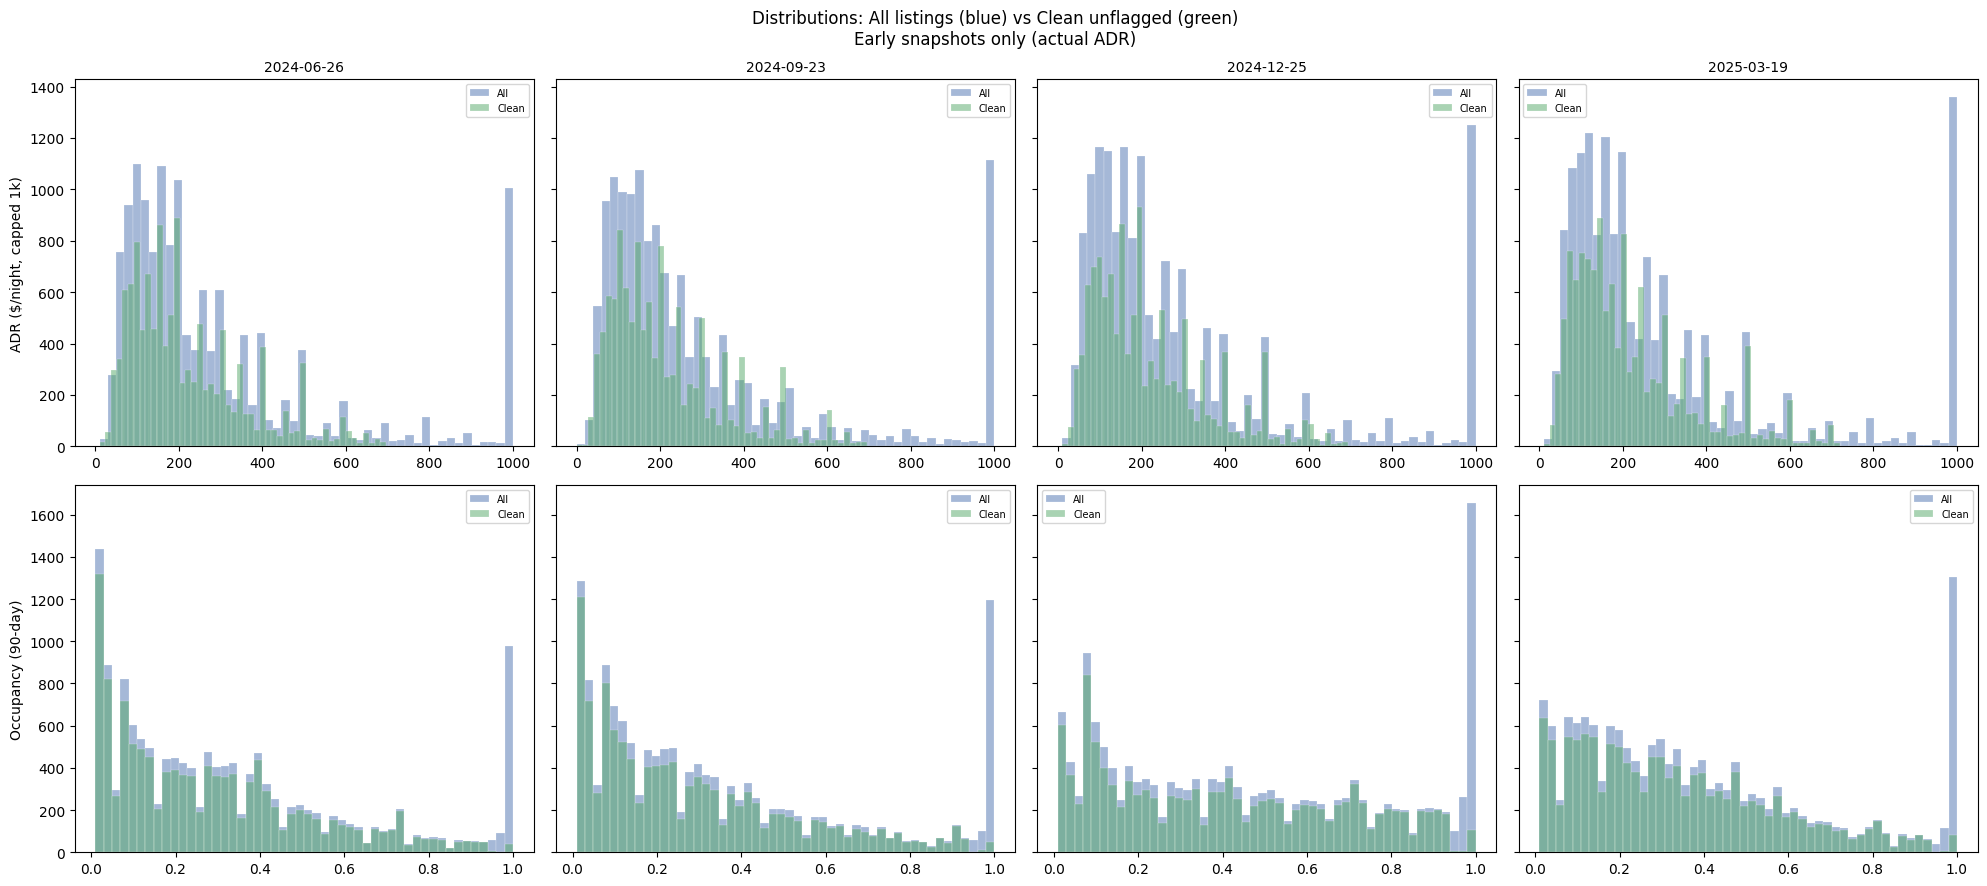

In [18]:
# --- Visual: ADR & Occupancy distributions — All vs Clean, per snapshot ---
early_snaps = sorted(df['snapshot_date'].unique())

fig, axes = plt.subplots(2, len(early_snaps), figsize=(5 * len(early_snaps), 9),
                         sharex='row', sharey='row')
if len(early_snaps) == 1:
    axes = axes.reshape(-1, 1)

for col_i, snap in enumerate(early_snaps):
    sub = df[df['snapshot_date'] == snap]
    all_adr   = sub['adr'].clip(upper=1000)
    clean_adr = sub.loc[~sub['any_flag'], 'adr'].clip(upper=1000)

    # Row 0: ADR
    ax = axes[0, col_i]
    ax.hist(all_adr, bins=50, alpha=0.5, color='#4C72B0', label='All', edgecolor='white', linewidth=0.3)
    ax.hist(clean_adr, bins=50, alpha=0.5, color='#55A868', label='Clean', edgecolor='white', linewidth=0.3)
    ax.set_title(snap, fontsize=10)
    if col_i == 0:
        ax.set_ylabel('Count')
    ax.legend(fontsize=7)

    # Row 1: Occupancy
    all_occ   = sub['occ_90'].dropna()
    clean_occ = sub.loc[~sub['any_flag'], 'occ_90'].dropna()
    ax2 = axes[1, col_i]
    ax2.hist(all_occ, bins=50, alpha=0.5, color='#4C72B0', label='All', edgecolor='white', linewidth=0.3)
    ax2.hist(clean_occ, bins=50, alpha=0.5, color='#55A868', label='Clean', edgecolor='white', linewidth=0.3)
    if col_i == 0:
        ax2.set_ylabel('Count')
    ax2.legend(fontsize=7)

axes[0, 0].set_ylabel('ADR ($/night, capped 1k)')
axes[1, 0].set_ylabel('Occupancy (90-day)')
fig.suptitle('Distributions: All listings (blue) vs Clean unflagged (green)\n'
             'Early snapshots only (actual ADR)', fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

=== % change: Clean vs All (positive = clean is higher) ===
snapshot_date  mean_adr_pct_chg  median_adr_pct_chg  std_adr_pct_chg  mean_occ_pct_chg  median_occ_pct_chg  mean_revpar_pct_chg  median_revpar_pct_chg
   2024-06-26            -42.46               -7.54           -90.65            -15.96              -11.54               -49.93                 -25.39
   2024-09-23            -45.75               -9.55           -92.37            -18.13              -12.50               -50.81                 -26.04
   2024-12-25            -47.80               -8.04           -92.77            -13.36               -9.52               -47.84                 -25.80
   2025-03-19            -45.90               -9.55           -91.28            -14.36               -6.45               -50.98                 -24.40

Interpretation:
  Positive mean_adr_pct_chg  → flagged listings had lower ADR (dragging mean down)
  Negative mean_adr_pct_chg  → flagged listings had higher ADR (luxury outliers)
  Ne

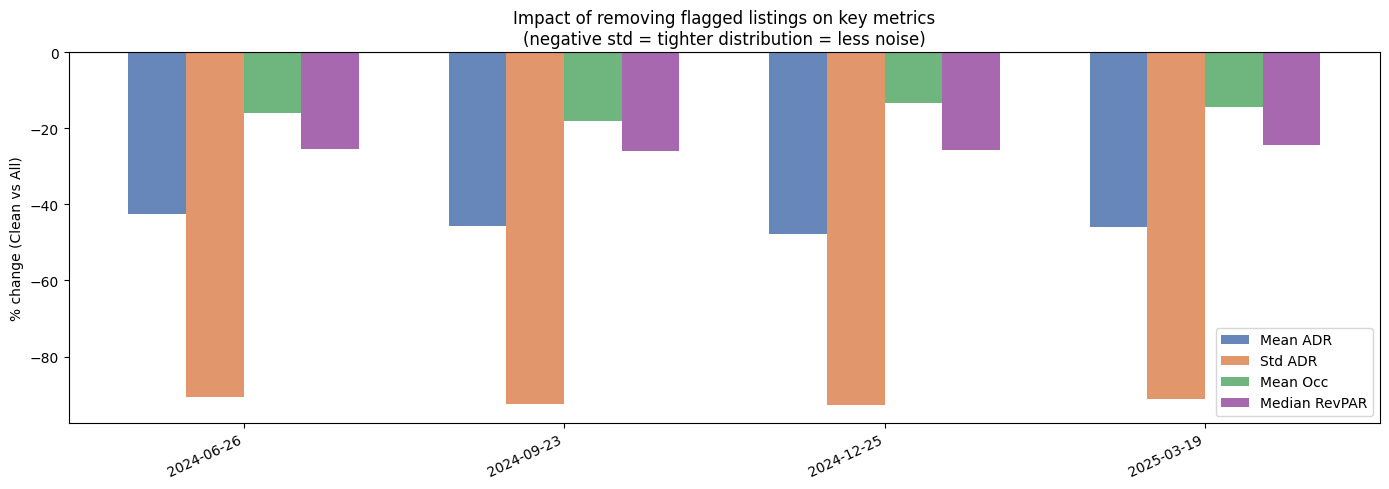

In [19]:
# --- Delta summary: how much do the flags shift the headline numbers? ---
pivot = df_stats.pivot(index='snapshot_date', columns='cohort')

delta = pd.DataFrame({'snapshot_date': pivot.index})
for metric in ['mean_adr', 'median_adr', 'std_adr', 'mean_occ', 'median_occ',
               'mean_revpar', 'median_revpar']:
    all_vals   = pivot[(metric, 'all')].values
    clean_vals = pivot[(metric, 'clean')].values
    pct_chg = np.where(
        (all_vals != 0) & ~np.isnan(all_vals.astype(float)),
        np.round(100 * (clean_vals.astype(float) - all_vals.astype(float))
                 / np.abs(all_vals.astype(float)), 2),
        np.nan
    )
    delta[f'{metric}_pct_chg'] = pct_chg

print('=== % change: Clean vs All (positive = clean is higher) ===')
print(delta.to_string(index=False))
print()
print('Interpretation:')
print('  Positive mean_adr_pct_chg  → flagged listings had lower ADR (dragging mean down)')
print('  Negative mean_adr_pct_chg  → flagged listings had higher ADR (luxury outliers)')
print('  Negative std_adr_pct_chg   → clean subset is tighter (flags removed noise)')
print('  Positive mean_occ_pct_chg  → flagged listings had lower occupancy (zero-occ removed)')

# --- Bar chart: % shift in key metrics ---
metrics_to_plot = ['mean_adr_pct_chg', 'std_adr_pct_chg', 'mean_occ_pct_chg', 'median_revpar_pct_chg']
labels_plot     = ['Mean ADR', 'Std ADR', 'Mean Occ', 'Median RevPAR']
colors_plot     = ['#4C72B0', '#DD8452', '#55A868', '#984ea3']

fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(delta))
width = 0.18
for i, (col, lbl, clr) in enumerate(zip(metrics_to_plot, labels_plot, colors_plot)):
    vals = delta[col].astype(float).values
    ax.bar(x + (i - 1.5) * width, vals, width, label=lbl, color=clr, alpha=0.85)

ax.axhline(0, color='grey', linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(delta['snapshot_date'], rotation=25, ha='right')
ax.set_ylabel('% change (Clean vs All)')
ax.set_title('Impact of removing flagged listings on key metrics\n'
             '(negative std = tighter distribution = less noise)')
ax.legend()
fig.tight_layout()
plt.show()

### 11b  Flag-by-flag isolation

The all-or-nothing view above removes ~30 % of listings at once.  Which
individual flag is doing the heavy lifting?  For each flag we exclude
**only** listings carrying that single flag and measure the % shift in
mean ADR, std ADR, mean occupancy, and median RevPAR vs. the full set.

This tells us whether the −40 % mean-ADR swing is driven primarily by
`adr_outlier` (luxury tail), `occ_zero` (inactive listings with weird ADR),
or some combination.

In [20]:
# --- Flag-by-flag isolation: exclude ONE flag at a time ---
flag_names = ['flag_adr_outlier', 'flag_adr_spike', 'flag_occ_saturated',
              'flag_occ_zero', 'flag_low_coverage']
flag_labels = ['ADR outlier', 'ADR spike', 'Occ saturated',
               'Occ zero', 'Low coverage']

# Restrict to early snapshots where flags are meaningful
df_early = df.copy()

metrics_keys = ['mean_adr', 'std_adr', 'mean_occ', 'median_revpar']

def calc_metrics(sub):
    return {
        'mean_adr':      sub['adr'].mean(),
        'std_adr':       sub['adr'].std(),
        'mean_occ':      sub['occ_90'].mean() if sub['occ_90'].notna().any() else np.nan,
        'median_revpar': sub['revpar_90'].median() if sub['revpar_90'].notna().any() else np.nan,
    }

rows = []
for snap in sorted(df_early['snapshot_date'].unique()):
    sub_all = df_early[df_early['snapshot_date'] == snap]
    base = calc_metrics(sub_all)

    for flag_col, flag_lbl in zip(flag_names, flag_labels):
        excluded = sub_all[flag_col].sum()
        sub_excl = sub_all[~sub_all[flag_col]]
        excl_m = calc_metrics(sub_excl)

        row = {
            'snapshot': snap,
            'excluded_flag': flag_lbl,
            'n_excluded': int(excluded),
            'pct_excluded': round(100 * excluded / len(sub_all), 1),
        }
        for mk in metrics_keys:
            if base[mk] and base[mk] != 0 and not np.isnan(base[mk]):
                row[f'{mk}_pct_chg'] = round(100 * (excl_m[mk] - base[mk]) / abs(base[mk]), 2)
            else:
                row[f'{mk}_pct_chg'] = np.nan
        rows.append(row)

df_iso = pd.DataFrame(rows)
print('=== Flag-by-flag impact (early snapshots, each flag excluded independently) ===')
print(df_iso.to_string(index=False))

=== Flag-by-flag impact (early snapshots, each flag excluded independently) ===
  snapshot excluded_flag  n_excluded  pct_excluded  mean_adr_pct_chg  std_adr_pct_chg  mean_occ_pct_chg  median_revpar_pct_chg
2024-06-26   ADR outlier        1466          10.2            -42.84           -90.62              0.88                 -13.99
2024-06-26     ADR spike           0           0.0              0.00             0.00              0.00                   0.00
2024-06-26 Occ saturated        1078           7.5              0.98             0.87            -16.14                 -12.21
2024-06-26      Occ zero           0           0.0              0.00             0.00              0.00                   0.00
2024-06-26  Low coverage           0           0.0              0.00             0.00              0.00                   0.00
2024-09-23   ADR outlier        1551          10.7            -46.25           -92.36              1.53                 -14.77
2024-09-23     ADR spike       

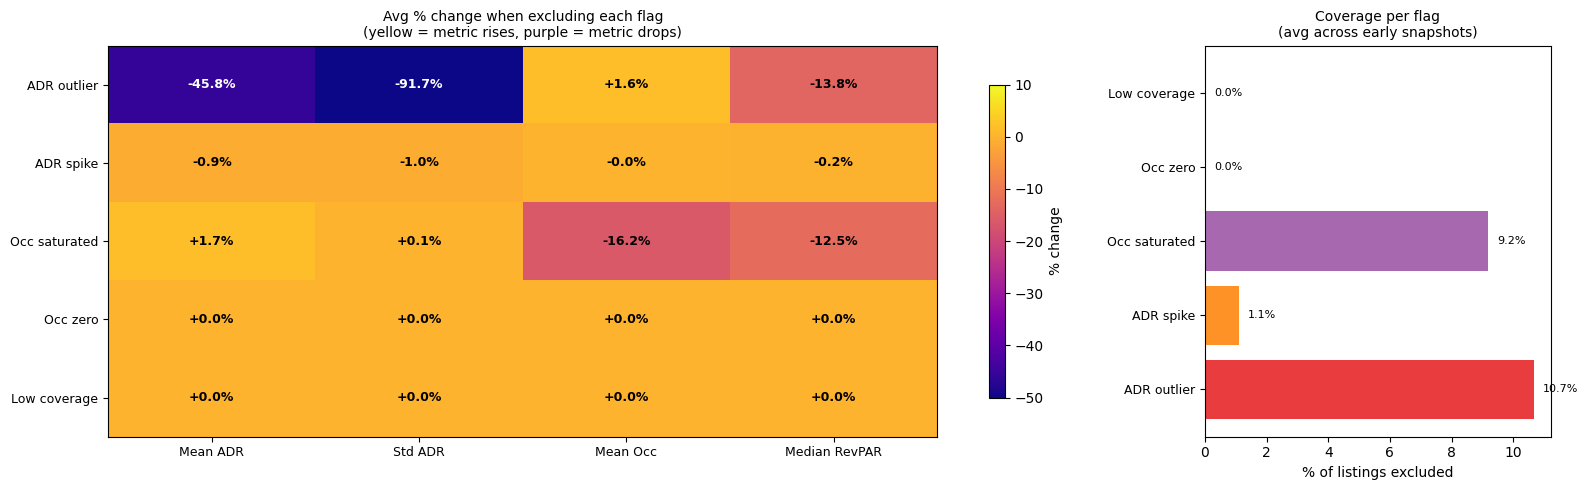

Biggest driver of mean ADR shift:  ADR outlier (-45.8%)
Biggest driver of std ADR shift:   ADR outlier (-91.7%)
Biggest driver of mean occ shift:  Occ saturated (-16.2%)


In [21]:
# --- Heatmap: flag-by-flag % change, averaged across early snapshots ---
avg_iso = (
    df_iso.groupby('excluded_flag')
    [['mean_adr_pct_chg', 'std_adr_pct_chg', 'mean_occ_pct_chg', 'median_revpar_pct_chg',
      'pct_excluded']]
    .mean()
    .reindex(flag_labels)      # preserve original flag order
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5),
                         gridspec_kw={'width_ratios': [3, 1]})

# Left: heatmap of % change (yellow=high/100%, purple=low/0%)
metric_cols = ['mean_adr_pct_chg', 'std_adr_pct_chg', 'mean_occ_pct_chg', 'median_revpar_pct_chg']
metric_labels = ['Mean ADR', 'Std ADR', 'Mean Occ', 'Median RevPAR']
hm_data = avg_iso[metric_cols].values

ax = axes[0]
im = ax.imshow(hm_data, cmap='plasma', aspect='auto', vmin=-50, vmax=10)
ax.set_xticks(range(len(metric_labels)))
ax.set_xticklabels(metric_labels, fontsize=9)
ax.set_yticks(range(len(flag_labels)))
ax.set_yticklabels(flag_labels, fontsize=9)

# Annotate cells
for i in range(len(flag_labels)):
    for j in range(len(metric_labels)):
        val = hm_data[i, j]
        if not np.isnan(val):
            color = 'white' if abs(val) > 25 else 'black'
            ax.text(j, i, f'{val:+.1f}%', ha='center', va='center',
                    fontsize=9, fontweight='bold', color=color)

ax.set_title('Avg % change when excluding each flag\n'
             '(yellow = metric rises, purple = metric drops)', fontsize=10)
fig.colorbar(im, ax=ax, label='% change', shrink=0.8)

# Right: how many listings each flag removes
ax2 = axes[1]
ax2.barh(range(len(flag_labels)), avg_iso['pct_excluded'].values,
         color=['#e41a1c', '#ff7f00', '#984ea3', '#377eb8', '#4daf4a'],
         alpha=0.85)
ax2.set_yticks(range(len(flag_labels)))
ax2.set_yticklabels(flag_labels, fontsize=9)
ax2.set_xlabel('% of listings excluded')
ax2.set_title('Coverage per flag\n(avg across early snapshots)', fontsize=10)
for i, v in enumerate(avg_iso['pct_excluded'].values):
    ax2.text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=8)

fig.tight_layout()
plt.show()

# --- Print the winner ---
biggest_adr_driver = avg_iso['mean_adr_pct_chg'].abs().idxmax()
biggest_std_driver = avg_iso['std_adr_pct_chg'].abs().idxmax()
biggest_occ_driver = avg_iso['mean_occ_pct_chg'].abs().idxmax()
print(f'Biggest driver of mean ADR shift:  {biggest_adr_driver} '
      f'({avg_iso.loc[biggest_adr_driver, "mean_adr_pct_chg"]:+.1f}%)')
print(f'Biggest driver of std ADR shift:   {biggest_std_driver} '
      f'({avg_iso.loc[biggest_std_driver, "std_adr_pct_chg"]:+.1f}%)')
print(f'Biggest driver of mean occ shift:  {biggest_occ_driver} '
      f'({avg_iso.loc[biggest_occ_driver, "mean_occ_pct_chg"]:+.1f}%)')